# Clustering Pengelolaan Sampah SIPSN (K-Means)
**Kelas Praktikum | Data Science IF-D**

Proyek ini mengelompokkan kabupaten/kota berdasarkan indikator timbulan dan pengelolaan sampah dari **SIPSN** (Sistem Informasi Pengelolaan Sampah Nasional) untuk mendukung identifikasi prioritas intervensi.

Anggota kelompok: Muhammad Hasan Rabbani (123240005) · M. Diandra Al Fashya Munandar (123240022) · Muhammad Faaiz (123240009) · Arilda Sarifah Umahatika (123240030)

---
### Alur notebook
| Bagian | Isi |
|---|---|
| 0 | Setup, konfigurasi, fungsi bantu |
| 1 | Data understanding & kamus data |
| 2 | Audit kualitas data (missing, outlier, duplikasi, **pola missing & verifikasi**) |
| 3 | Cleaning & imputasi |
| 4 | EDA (statistik, representativitas, visualisasi, korelasi, rekonsiliasi) |
| 5 | Preprocessing & seleksi fitur (encoding, imbalance, split, log1p + scaling) |
| 6 | **Pemodelan K-Means** (pemilihan K, profil klaster, PCA, uji sensitivitas) |
| 7 | Kesimpulan & keterbatasan |

### Cara menjalankan
1. Taruh file `Statistik_Pengelolaan_Sampah_*.xls` di folder yang sama dengan notebook ini (atau di `data/`).
2. `pip install -r requirements.txt`, lalu **Run All**. Di Google Colab, notebook akan meminta unggah file data.
3. Semua grafik (PNG) dan tabel (CSV) otomatis tersimpan di folder `output/`.

> **Catatan perubahan dari skrip `.py`:** bagian 1-5 adalah konversi `analisis_sampah_revisi.py` (hasil angkanya dicek identik dengan `output/` lama). Yang baru: bagian 2.5 (pola missing), flag kualitas data, bagian 4.1 (rekonsiliasi dengan tabel ringkasan resmi), dan **bagian 6 (pemodelan)** yang sebelumnya belum ada.

## 0. Setup & konfigurasi

In [1]:
# Jalankan sekali jika ada library yang belum terpasang (hapus tanda # lalu run):
# %pip install -q lxml pandas numpy matplotlib seaborn scikit-learn

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
# ===================== KONFIGURASI (ubah di sini) =====================
SHOW_PLOTS = True             # True = grafik tampil di notebook (tetap disimpan ke output/)
IMPUTASI_BSU_BSI = 'median'   # 'median' (dianggap "tidak melapor") atau 'nol' (dianggap "tidak ada fasilitas")
MEDIAN_DARI_TRAIN = False     # False = median seluruh data (sama dengan skrip lama); True = median data train saja (tanpa kebocoran)
TEST_SIZE = 0.20
RANDOM_STATE = 42
AMBANG_REDUNDAN = 0.80        # |rho Spearman| >= ini => fitur turunan dianggap redundan
NAMA_FILE_POLA = 'Statistik_Pengelolaan_Sampah_*.xls'

K_MIN, K_MAX = 2, 10          # rentang K yang diuji
K_AKHIR = 3                   # K yang dipakai model akhir (lihat pembahasan di bagian 6.1)
N_INIT = 20                   # jumlah inisialisasi acak K-Means (makin besar makin stabil)
# ======================================================================

def cari_file_data():
    """Cari file SIPSN di folder kerja, folder induk, atau ./data."""
    for folder in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'data']:
        hasil = sorted(folder.glob(NAMA_FILE_POLA))
        if hasil:
            return hasil[-1]
    return None

file_path = cari_file_data()
if file_path is None:
    try:                                   # Google Colab: unggah manual
        from google.colab import files
        print("Unggah file Statistik_Pengelolaan_Sampah_*.xls ...")
        files.upload()
        file_path = cari_file_data()
    except ImportError:
        pass
if file_path is None:
    raise FileNotFoundError(f"Tidak ada file '{NAMA_FILE_POLA}' di {Path.cwd()} (atau folder induk / data/).")

BASE_DIR = file_path.parent
OUT_DIR = BASE_DIR / 'output'
OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

print("File data  :", file_path.name)
print("Folder output:", OUT_DIR)

File data  : Statistik_Pengelolaan_Sampah_2026_2026-10-22.xls
Folder output: c:\ds\clustering-pengelolaan-sampah-sipsn-notebook\clustering-pengelolaan-sampah-sipsn\output


In [3]:
# ===================== FUNGSI BANTU =====================
def simpan_fig(nama):
    plt.tight_layout()
    plt.savefig(OUT_DIR / nama, dpi=200, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close()


def simpan_tabel(df, nama, index=True):
    df.to_csv(OUT_DIR / nama, index=index, encoding='utf-8-sig')


_POLA_RIBUAN_ID = re.compile(r'^\d{1,3}(\.\d{3})+(,\d+)?$')   # '2.784' atau '2.784,5' (format Indonesia)


def ke_numerik(s):
    """Ubah kolom ke angka. Mengenali 3 bentuk teks:
       '2.784,0' (Indonesia, ribuan titik) | '42,7' (koma desimal) | '2784.0' (sudah dinormalkan pandas)."""
    if pd.api.types.is_numeric_dtype(s):
        return s

    def konversi(v):
        if pd.isna(v):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        t = str(v).strip()
        if _POLA_RIBUAN_ID.match(t):
            t = t.replace('.', '').replace(',', '.')
        elif ',' in t:
            t = t.replace(',', '.')
        try:
            return float(t)
        except ValueError:
            return np.nan
    return s.map(konversi)


def normalisasi_persen(s):
    """Jika skala persen terbaca basis 10.000, ubah ke 0-100."""
    return s / 100.0 if s.max() > 100 else s


def audit_kolom(df, kolom_num):
    """Audit per kolom: missing, outlier (IQR), nilai nol, nilai berulang."""
    rows = []
    for c in df.columns:
        s = df[c]
        row = {
            'Kolom': c,
            'Tipe': 'Numerik' if c in kolom_num else 'Kategori/Lainnya',
            'Missing': int(s.isna().sum()),
            'Missing_%': round(s.isna().mean() * 100, 2),
            'Nilai_unik': int(s.nunique()),
            'Nilai_berulang': int(s.dropna().duplicated().sum()),
            'Outlier_IQR': np.nan,
            'Outlier_%': np.nan,
            'Nilai_nol': np.nan,
        }
        if c in kolom_num:
            q1, q3 = s.quantile([.25, .75])
            iqr = q3 - q1
            n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
            row['Outlier_IQR'] = n_out
            row['Outlier_%'] = round(n_out / s.notna().sum() * 100, 2)
            row['Nilai_nol'] = int((s == 0).sum())
        rows.append(row)
    return pd.DataFrame(rows).set_index('Kolom')


def kekuatan(r):
    a = abs(r)
    return 'lemah' if a < 0.3 else 'sedang' if a < 0.5 else 'cukup kuat' if a < 0.7 else 'kuat'


def kelompok_rips(v):
    """Gabungkan status RIPS yang terlalu rinci (beberapa hanya 2-5 wilayah) menjadi 4 kelompok."""
    t = str(v).strip().lower()
    if t == 'ada dan sudah disahkan':
        return 'Disahkan'
    if t == 'tidak ada':
        return 'Tidak ada'
    if t.startswith('ada') or t in ('dalam perencanaan', 'tidak sesuai'):
        return 'Ada, belum final'
    return 'Tidak diketahui'            # 'Belum ada informasi', 'Tidak diisi', dll.

## 1. Data understanding & kamus data
File `.xls` dari SIPSN sebenarnya **dokumen HTML** (bukan Excel biner), sehingga dibaca dengan `pd.read_html`, bukan `read_excel`. Parameter `thousands='.'` dan `decimal=','` dipakai karena format angka Indonesia. File berisi 3 tabel: ringkasan indikator nasional, ringkasan wilayah & fasilitas, dan **tabel data per wilayah** (yang terbesar).

In [4]:
tables = pd.read_html(file_path, thousands='.', decimal=',')
print(f"Jumlah tabel terbaca: {len(tables)}")
for i, t in enumerate(tables):
    print(f"  tabel[{i}] ukuran {t.shape}")

df_raw = max(tables, key=len).copy()          # tabel data wilayah = tabel dengan baris terbanyak
df_raw.columns = df_raw.columns.astype(str).str.strip()
print(f"\nTabel utama dipakai: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
df_raw.head()

Jumlah tabel terbaca: 3
  tabel[0] ukuran (11, 2)
  tabel[1] ukuran (14, 2)
  tabel[2] ukuran (519, 20)

Tabel utama dipakai: 519 baris, 20 kolom


,No,Provinsi,Kota/Kabupaten,Jenis TPA,Nama TPA,Kelompok,BSU Aktif,BSU Tidak Aktif,Sampah Terkelola BSU,BSI Aktif,BSI Tidak Aktif,Sampah Terkelola BSI,Status RIPS,Link RIPS,Verifikasi Lapangan,Nilai Kinerja PS,Progress SA,Timbulan (tpd),% S. Terkelola,% S. Belum Terkelola
0,1,Jawa Barat,Kabupaten Bogor,Open Dumping,-,343 TPA (353 Kota/Kab),380,0,190.000,6,0,30.000,Ada (Draft) tapi Belum Disahkan,https://drive.google.com/file/d/15mAtMwne_2kF7...,Sudah,-,5415,2784,22.100,77.900
1,2,Banten,Kabupaten Tangerang,Open Dumping,-,343 TPA (353 Kota/Kab),123,29,1.700,1,0,108.000,Ada tapi Belum Disahkan,-,Sudah,-,662,2663,4.380,95.620
2,3,DKI Jakarta,Kota Jakarta Timur,Open Dumping,-,Diluar 343 TPA (171 Kota/Kab),333,0,5.550,1,0,0.080,Ada dan Sudah Disahkan,https://drive.google.com/file/d/11Yiz2oo4zKm83...,Sudah,-,-,2455,16.280,83.720
3,4,Jawa Barat,Kabupaten Bekasi,Open Dumping,-,343 TPA (353 Kota/Kab),257,225,25.700,0,0,0.000,Ada dan Sudah Disahkan,-,Sudah,-,4385,2404,2.580,97.420
4,5,DKI Jakarta,Kota Jakarta Selatan,Open Dumping,-,Diluar 343 TPA (171 Kota/Kab),495,0,10.570,1,0,0.620,Ada dan Sudah Disahkan,https://drive.google.com/file/d/11Yiz2oo4zKm83...,Sudah,-,-,2005,19.970,80.030


In [5]:
data_dictionary = pd.DataFrame([
    ['Provinsi', 'Kategori (teks)', 'Nama provinsi', 'Identitas geografis', 'Identitas'],
    ['Kota/Kabupaten', 'Kategori (teks)', 'Nama wilayah', 'Identitas; dasar Jenis_Wilayah (Kabupaten vs Kota)', 'Identitas'],
    ['Timbulan (tpd)', 'Numerik (integer)', 'Ton/hari', 'Volume sampah', 'Fitur K-Means'],
    ['% S. Terkelola', 'Numerik (float)', 'Persen (0-100)', 'Kinerja penanganan sampah', 'Fitur K-Means'],
    ['BSU Aktif', 'Numerik (integer)', 'Unit', 'Bank Sampah Unit aktif (akses infrastruktur)', 'Fitur K-Means'],
    ['BSI Aktif', 'Numerik (integer)', 'Unit', 'Bank Sampah Induk aktif (akses infrastruktur)', 'Fitur K-Means'],
    ['BSU Tidak Aktif', 'Numerik (integer)', 'Unit', 'Bank sampah unit tidak aktif', 'Tidak dipakai'],
    ['BSI Tidak Aktif', 'Numerik (integer)', 'Unit', 'Bank sampah induk tidak aktif', 'Tidak dipakai'],
    ['Sampah Terkelola BSU', 'Numerik', 'Cek satuan di portal SIPSN', 'Sampah yang dikelola bank sampah unit', 'Kandidat fitur UAS'],
    ['Sampah Terkelola BSI', 'Numerik', 'Cek satuan di portal SIPSN', 'Sampah yang dikelola bank sampah induk', 'Kandidat fitur UAS'],
    ['% S. Belum Terkelola', 'Numerik (float)', 'Persen (0-100)', 'Komplemen dari % S. Terkelola (diverifikasi di bagian 5.3)', 'Dibuang (redundan)'],
    ['Jenis TPA', 'Kategori (teks)', 'Sanitary/Controlled/Open dumping/dll', 'Jenis tempat pemrosesan akhir', 'Profiling klaster'],
    ['Status RIPS', 'Kategori (teks)', 'Status dokumen', 'Status rencana induk pengelolaan sampah', 'Profiling klaster'],
    ['Kelompok', 'Kategori (teks)', '-', 'Daftar program "343 TPA" (bukan klasifikasi kota/kabupaten)', 'Profiling klaster'],
    ['Verifikasi Lapangan', 'Kategori (teks)', 'Sudah / Belum', 'Status verifikasi data oleh pusat', 'Flag kualitas data'],
    ['Nama TPA', 'Teks', '-', 'Nama TPA', 'Dibuang (kosong 100%)'],
    ['Nilai Kinerja PS', 'Numerik', '-', 'Nilai kinerja', 'Dibuang (kosong 100%)'],
    ['Link RIPS', 'Teks (URL)', '-', 'Tautan dokumen RIPS', 'Dibuang (banyak kosong)'],
    ['Progress SA', 'Numerik', '-', 'Progres', 'Dibuang (banyak kosong)'],
    ['No', 'Integer', '-', 'Nomor urut baris', 'Dibuang (bukan informasi)'],
], columns=['Variabel', 'Tipe Data', 'Satuan/Format', 'Makna', 'Peran'])
data_dictionary['Dtype terbaca'] = data_dictionary['Variabel'].map(
    lambda v: str(df_raw[v].dtype) if v in df_raw.columns else '(tidak ada di data)')
simpan_tabel(data_dictionary, 'tabel_kamus_data.csv', index=False)
data_dictionary

,Variabel,Tipe Data,Satuan/Format,Makna,Peran,Dtype terbaca
0,Provinsi,Kategori (teks),Nama provinsi,Identitas geografis,Identitas,object
1,Kota/Kabupaten,Kategori (teks),Nama wilayah,Identitas; dasar Jenis_Wilayah (Kabupaten vs K...,Identitas,object
2,Timbulan (tpd),Numerik (integer),Ton/hari,Volume sampah,Fitur K-Means,int64
3,% S. Terkelola,Numerik (float),Persen (0-100),Kinerja penanganan sampah,Fitur K-Means,float64
4,BSU Aktif,Numerik (integer),Unit,Bank Sampah Unit aktif (akses infrastruktur),Fitur K-Means,object
5,BSI Aktif,Numerik (integer),Unit,Bank Sampah Induk aktif (akses infrastruktur),Fitur K-Means,object
6,BSU Tidak Aktif,Numerik (integer),Unit,Bank sampah unit tidak aktif,Tidak dipakai,object
7,BSI Tidak Aktif,Numerik (integer),Unit,Bank sampah induk tidak aktif,Tidak dipakai,object
8,Sampah Terkelola BSU,Numerik,Cek satuan di portal SIPSN,Sampah yang dikelola bank sampah unit,Kandidat fitur UAS,float64
9,Sampah Terkelola BSI,Numerik,Cek satuan di portal SIPSN,Sampah yang dikelola bank sampah induk,Kandidat fitur UAS,float64


## 2. Kualitas data (audit missing, outlier, duplikasi)
Tanda `-` di data SIPSN berarti kosong, jadi diganti `NaN`. Baris yang kolom **Kota/Kabupaten**-nya kosong adalah baris sisa/kosong dan dibuang.

In [6]:
numeric_features = ['Timbulan (tpd)', '% S. Terkelola', 'BSU Aktif', 'BSI Aktif']

df_audit = df_raw.mask(df_raw == '-')               # "-" = penanda kosong
base = df_audit.dropna(subset=['Kota/Kabupaten']).copy()
print(f"Baris mentah: {len(df_raw)} | baris kosong dibuang: {len(df_raw) - len(base)} | baris valid: {len(base)}")

# 2.1 Cek konversi angka (menangkap nilai yang gagal terbaca)
num_before = base[numeric_features].apply(ke_numerik)
gagal = [{'Kolom': c, 'Gagal_dikonversi': int((base[c].notna() & num_before[c].isna()).sum())}
         for c in numeric_features]
print("\nCek konversi angka (harus 0 semua):")
display(pd.DataFrame(gagal).set_index('Kolom'))

Baris mentah: 519 | baris kosong dibuang: 8 | baris valid: 511

Cek konversi angka (harus 0 semua):


,Gagal_dikonversi
Kolom,
Timbulan (tpd),0
% S. Terkelola,0
BSU Aktif,0
BSI Aktif,0


In [7]:
# 2.2 Audit per kolom
base_audit = base.copy()
base_audit[numeric_features] = num_before
tabel_audit = audit_kolom(base_audit, numeric_features)
simpan_tabel(tabel_audit, 'tabel_audit_kolom.csv')
display(tabel_audit)

print("Ringkasan missing (hanya kolom yang punya missing):")
display(tabel_audit.loc[tabel_audit['Missing'] > 0, ['Missing', 'Missing_%']])

,Tipe,Missing,Missing_%,Nilai_unik,Nilai_berulang,Outlier_IQR,Outlier_%,Nilai_nol
Kolom,,,,,,,,
No,Kategori/Lainnya,0,0.000,511,0,NaN,NaN,NaN
Provinsi,Kategori/Lainnya,0,0.000,38,473,NaN,NaN,NaN
Kota/Kabupaten,Kategori/Lainnya,0,0.000,511,0,NaN,NaN,NaN
Jenis TPA,Kategori/Lainnya,44,8.610,4,463,NaN,NaN,NaN
Nama TPA,Kategori/Lainnya,511,100.000,0,0,NaN,NaN,NaN
Kelompok,Kategori/Lainnya,0,0.000,2,509,NaN,NaN,NaN
BSU Aktif,Numerik,26,5.090,127,358,70.000,14.430,135.000
BSU Tidak Aktif,Kategori/Lainnya,29,5.680,71,411,NaN,NaN,NaN
Sampah Terkelola BSU,Kategori/Lainnya,0,0.000,174,337,NaN,NaN,NaN


Ringkasan missing (hanya kolom yang punya missing):


,Missing,Missing_%
Kolom,,
Jenis TPA,44,8.610
Nama TPA,511,100.000
BSU Aktif,26,5.090
BSU Tidak Aktif,29,5.680
BSI Aktif,29,5.680
BSI Tidak Aktif,32,6.260
Status RIPS,15,2.940
Link RIPS,373,72.990
Nilai Kinerja PS,511,100.000


In [8]:
# 2.3 Duplikasi
dups_baris = int(base.duplicated().sum())
dups_kunci = int(base.duplicated(subset=['Provinsi', 'Kota/Kabupaten']).sum())
print(f"Duplikat baris penuh                 : {dups_baris}")
print(f"Duplikat kunci (Provinsi+Kota/Kab)   : {dups_kunci}")
print(f"Wilayah unik                          : {base[['Provinsi', 'Kota/Kabupaten']].drop_duplicates().shape[0]}")

# 2.4 Outlier & nilai nol (keputusan: dipertahankan, diredam log1p)
print("\nOutlier (IQR) & nilai nol pada fitur numerik:")
display(tabel_audit.loc[numeric_features, ['Outlier_IQR', 'Outlier_%', 'Nilai_nol']])
nol_timbulan = num_before['Timbulan (tpd)'].eq(0)
print(f"Wilayah dengan timbulan = 0: {int(nol_timbulan.sum())} "
      f"(kemungkinan belum melapor; dipertahankan dan diberi flag, bukan dihapus)")
if nol_timbulan.any():
    print(base.loc[nol_timbulan, ['Provinsi', 'Kota/Kabupaten', '% S. Terkelola']].to_string(index=False))

Duplikat baris penuh                 : 0
Duplikat kunci (Provinsi+Kota/Kab)   : 0
Wilayah unik                          : 511

Outlier (IQR) & nilai nol pada fitur numerik:


,Outlier_IQR,Outlier_%,Nilai_nol
Kolom,,,
Timbulan (tpd),56.000,10.960,1.000
% S. Terkelola,25.000,4.890,64.000
BSU Aktif,70.000,14.430,135.000
BSI Aktif,20.000,4.150,193.000


Wilayah dengan timbulan = 0: 1 (kemungkinan belum melapor; dipertahankan dan diberi flag, bukan dihapus)
Provinsi     Kota/Kabupaten  % S. Terkelola
    Aceh Kabupaten Simeulue          13.000


### 2.5 Pola missing & status verifikasi *(baru)*
Imputasi median hanya valid jika data hilang **secara acak**. Sel di bawah menguji asumsi itu: apakah kolom yang kosong saling berkaitan, dan apakah nilai `0%` terkelola berkaitan dengan wilayah yang **belum diverifikasi lapangan**?

In [9]:
flag_bsu_bsi_kosong = num_before[['BSU Aktif', 'BSI Aktif']].isna().any(axis=1)
flag_belum_verif = base['Verifikasi Lapangan'].eq('Belum')
nol_persen = num_before['% S. Terkelola'].eq(0)

pola = pd.DataFrame({
    'BSU kosong': num_before['BSU Aktif'].isna(),
    'BSI kosong': num_before['BSI Aktif'].isna(),
    'Jenis TPA kosong': base['Jenis TPA'].isna(),
    'Status RIPS kosong': base['Status RIPS'].isna(),
    'Belum verifikasi': flag_belum_verif,
    '% terkelola = 0': nol_persen,
}).astype(int)
print("Korelasi antar indikator 'kosong' (1 = selalu bersamaan):")
display(pola.corr().round(2))

print(f"BSU kosong & BSI kosong bersamaan: {int((pola['BSU kosong'] & pola['BSI kosong']).sum())} "
      f"dari {int(pola['BSU kosong'].sum())} (BSU) / {int(pola['BSI kosong'].sum())} (BSI)")
print(f"Wilayah belum verifikasi lapangan: {int(flag_belum_verif.sum())} dari {len(base)}")
print(f"Share wilayah 0% terkelola -> belum verifikasi: {nol_persen[flag_belum_verif].mean():.1%} | "
      f"sudah verifikasi: {nol_persen[~flag_belum_verif].mean():.1%}")
print(f"Wilayah 0% terkelola: {int(nol_persen.sum())} | di antaranya belum verifikasi: "
      f"{int((nol_persen & flag_belum_verif).sum())} | Jenis TPA kosong: {int((nol_persen & base['Jenis TPA'].isna()).sum())}")
print("\nRincian wilayah 0% terkelola (Jenis TPA x status verifikasi):")
display(pd.crosstab(base.loc[nol_persen, 'Jenis TPA'].fillna('(kosong)'), base.loc[nol_persen, 'Verifikasi Lapangan']))

Korelasi antar indikator 'kosong' (1 = selalu bersamaan):


,BSU kosong,BSI kosong,Jenis TPA kosong,Status RIPS kosong,Belum verifikasi,% terkelola = 0
BSU kosong,1.000,0.940,0.750,0.750,0.370,0.210
BSI kosong,0.940,1.000,0.710,0.710,0.390,0.190
Jenis TPA kosong,0.750,0.710,1.000,0.570,0.620,0.390
Status RIPS kosong,0.750,0.710,0.570,1.000,-0.040,-0.070
Belum verifikasi,0.370,0.390,0.620,-0.040,1.000,0.470
% terkelola = 0,0.210,0.190,0.390,-0.070,0.470,1.000


BSU kosong & BSI kosong bersamaan: 26 dari 26 (BSU) / 29 (BSI)
Wilayah belum verifikasi lapangan: 24 dari 511
Share wilayah 0% terkelola -> belum verifikasi: 83.3% | sudah verifikasi: 9.0%
Wilayah 0% terkelola: 64 | di antaranya belum verifikasi: 20 | Jenis TPA kosong: 24

Rincian wilayah 0% terkelola (Jenis TPA x status verifikasi):


Verifikasi Lapangan,Belum,Sudah
Jenis TPA,,
(kosong),20,4
Controlled Landfill,0,1
Open Dumping,0,32
Tidak memiliki TPA,0,7


**Temuan:** kekosongan `BSU` dan `BSI` hampir selalu muncul bersamaan dan berkaitan dengan `Jenis TPA` kosong, artinya itu pola **"wilayah belum melapor"**, bukan data hilang acak. Selain itu, mayoritas wilayah yang belum diverifikasi tercatat 0% terkelola. Jadi sebagian wilayah "0% terkelola" kemungkinan *tidak melapor*, bukan *tidak mengelola*. Karena itu bagian 3 menambahkan **flag kualitas data**, dan bagian 6 menguji seberapa sensitif klaster terhadap wilayah-wilayah ini.

## 3. Data cleaning & imputasi
Keputusan utama: kolom yang kosong ≥ ~57% dibuang; outlier **dipertahankan** (kondisi riil, diredam `log1p`); `BSU/BSI Aktif` yang `-` diimputasi (median atau nol sesuai konfigurasi); kategori kosong diisi `'Tidak diisi'`. Split train/test dibuat **di awal** agar median imputasi bisa dihitung hanya dari data train bila `MEDIAN_DARI_TRAIN = True`. Hasil split identik dengan skrip lama.

In [10]:
df_clean = base.copy()

# 3.1 Buang kolom non-informatif
cols_to_drop = ['Nama TPA', 'Nilai Kinerja PS', 'Progress SA', 'Link RIPS', 'No']
dibuang = [c for c in cols_to_drop if c in df_clean.columns]
df_clean.drop(columns=dibuang, inplace=True)
print("Kolom dibuang:", dibuang)

# 3.2 Jenis wilayah + split train/test (stratifikasi pada Jenis_Wilayah)
df_clean['Jenis_Wilayah'] = np.where(
    df_clean['Kota/Kabupaten'].str.startswith('Kabupaten'), 'Kabupaten (Proxy Desa)', 'Kota')
idx_train, idx_test = train_test_split(
    df_clean.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df_clean['Jenis_Wilayah'])
df_clean['Split'] = np.where(df_clean.index.isin(idx_train), 'train', 'test')

# 3.3 Flag kualitas data (dihitung SEBELUM imputasi)
df_clean['Flag_Timbulan_Nol'] = nol_timbulan
df_clean['Flag_BSU_BSI_Kosong'] = flag_bsu_bsi_kosong
df_clean['Flag_Belum_Verifikasi'] = flag_belum_verif
print(f"Flag: timbulan nol = {int(df_clean['Flag_Timbulan_Nol'].sum())} | BSU/BSI kosong = "
      f"{int(df_clean['Flag_BSU_BSI_Kosong'].sum())} | belum verifikasi = {int(df_clean['Flag_Belum_Verifikasi'].sum())}")

Kolom dibuang: ['Nama TPA', 'Nilai Kinerja PS', 'Progress SA', 'Link RIPS', 'No']
Flag: timbulan nol = 1 | BSU/BSI kosong = 29 | belum verifikasi = 24


In [11]:
# 3.4 Konversi numerik + imputasi
log_imputasi = []
for col in numeric_features:
    df_clean[col] = ke_numerik(df_clean[col])
    n_na = int(df_clean[col].isna().sum())
    if n_na > 0:
        if col in ['BSU Aktif', 'BSI Aktif'] and IMPUTASI_BSU_BSI == 'nol':
            nilai, metode = 0, 'nol (anggap "-" = tidak ada fasilitas)'
        else:
            ref = df_clean.loc[df_clean['Split'] == 'train', col] if MEDIAN_DARI_TRAIN else df_clean[col]
            nilai = ref.median()
            metode = 'median ' + ('(train saja)' if MEDIAN_DARI_TRAIN else '(seluruh data)')
        df_clean[col] = df_clean[col].fillna(nilai)
        log_imputasi.append({'Kolom': col, 'Jumlah_diisi': n_na, 'Metode': metode, 'Nilai': nilai})
df_clean['% S. Terkelola'] = normalisasi_persen(df_clean['% S. Terkelola'])
assert df_clean['% S. Terkelola'].between(0, 100).all(), "Ada % terkelola di luar 0-100"

# 3.5 Kategori
df_clean['Jenis TPA'] = df_clean['Jenis TPA'].fillna('Tidak diisi')
df_clean['Status RIPS'] = df_clean['Status RIPS'].fillna('Tidak diisi')
df_clean['RIPS_Grup'] = df_clean['Status RIPS'].map(kelompok_rips)

print("Log imputasi:")
display(pd.DataFrame(log_imputasi) if log_imputasi else "Tidak ada imputasi numerik")
print("Dasar pemilihan metode imputasi BSU/BSI:")
for col in ['BSU Aktif', 'BSI Aktif']:
    print(f"  {col}: nilai 0 dilaporkan eksplisit = {int(tabel_audit.loc[col, 'Nilai_nol'])} wilayah | "
          f"tanda '-' (tidak ada data) = {int(tabel_audit.loc[col, 'Missing'])} wilayah")
print("  -> '-' dibedakan dari 0: dianggap 'tidak melapor' (lihat 2.5)" if IMPUTASI_BSU_BSI == 'median'
      else "  -> '-' dianggap 'tidak ada fasilitas' dan diisi 0.")

Log imputasi:


,Kolom,Jumlah_diisi,Metode,Nilai
0,BSU Aktif,26,median (seluruh data),4.000
1,BSI Aktif,29,median (seluruh data),1.000


Dasar pemilihan metode imputasi BSU/BSI:
  BSU Aktif: nilai 0 dilaporkan eksplisit = 135 wilayah | tanda '-' (tidak ada data) = 26 wilayah
  BSI Aktif: nilai 0 dilaporkan eksplisit = 193 wilayah | tanda '-' (tidak ada data) = 29 wilayah
  -> '-' dibedakan dari 0: dianggap 'tidak melapor' (lihat 2.5)


In [12]:
# 3.6 Sebelum vs sesudah
nb = num_before.copy()
nb['% S. Terkelola'] = normalisasi_persen(nb['% S. Terkelola'])
sebelum_sesudah = pd.DataFrame({
    'Missing_sebelum': nb.isna().sum(),
    'Missing_sesudah': df_clean[numeric_features].isna().sum(),
    'Mean_sebelum': nb.mean(),
    'Mean_sesudah': df_clean[numeric_features].mean(),
    'Median_sebelum': nb.median(),
    'Median_sesudah': df_clean[numeric_features].median(),
    'Max_sebelum': nb.max(),
    'Max_sesudah': df_clean[numeric_features].max(),
})
print("Kondisi sebelum vs sesudah (fitur numerik):")
display(sebelum_sesudah)
simpan_tabel(sebelum_sesudah, 'tabel_sebelum_sesudah_numerik.csv')

kat_sebelum_sesudah = pd.DataFrame({
    'Missing_sebelum': base[['Jenis TPA', 'Status RIPS']].isna().sum(),
    'Missing_sesudah': df_clean[['Jenis TPA', 'Status RIPS']].isna().sum(),
    'Strategi': ["isi 'Tidak diisi'", "isi 'Tidak diisi'"],
})
print("Sebelum vs sesudah (kategori):")
display(kat_sebelum_sesudah)
simpan_tabel(kat_sebelum_sesudah, 'tabel_sebelum_sesudah_kategori.csv')

print(f"\nBentuk data: mentah {df_raw.shape} -> bersih {df_clean.shape}")
print(f"Total missing fitur numerik: sebelum {int(nb.isna().sum().sum())} -> sesudah {int(df_clean[numeric_features].isna().sum().sum())}")

Kondisi sebelum vs sesudah (fitur numerik):


,Missing_sebelum,Missing_sesudah,Mean_sebelum,Mean_sesudah,Median_sebelum,Median_sesudah,Max_sebelum,Max_sesudah
Timbulan (tpd),0,0,282.299,282.299,141.000,141.000,"2,784.000","2,784.000"
% S. Terkelola,0,0,22.848,22.848,11.890,11.890,99.460,99.460
BSU Aktif,26,0,46.466,44.305,4.000,4.000,857.000,857.000
BSI Aktif,29,0,0.853,0.861,1.000,1.000,16.000,16.000


Sebelum vs sesudah (kategori):


,Missing_sebelum,Missing_sesudah,Strategi
Jenis TPA,44,0,isi 'Tidak diisi'
Status RIPS,15,0,isi 'Tidak diisi'



Bentuk data: mentah (519, 20) -> bersih (511, 21)
Total missing fitur numerik: sebelum 55 -> sesudah 0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Statistik deskriptif & rekonsiliasi dengan tabel ringkasan resmi

In [13]:
stats_desc = df_clean[numeric_features].describe().T
stats_desc['Skewness'] = df_clean[numeric_features].skew()
simpan_tabel(stats_desc, 'tabel_statistik_deskriptif.csv')
display(stats_desc)

tim = df_clean['Timbulan (tpd)']
ter = df_clean['% S. Terkelola']
idx_max = tim.idxmax()
persen_lt10 = (ter < 10).mean() * 100
print("[Kesimpulan statistik deskriptif]")
print(f"- Timbulan: rata-rata {tim.mean():.1f} tpd | median {tim.median():.1f} tpd | "
      f"maksimum {tim.max():,.1f} tpd ({df_clean.loc[idx_max, 'Kota/Kabupaten']}) | skewness {tim.skew():.2f}")
print(f"- % terkelola: rata-rata {ter.mean():.1f}% | median {ter.median():.1f}%")
print(f"- {persen_lt10:.1f}% wilayah mengelola kurang dari 10% sampahnya")

,count,mean,std,min,25%,50%,75%,max,Skewness
Timbulan (tpd),511.000,282.299,381.869,0.000,76.500,141.000,310.000,"2,784.000",3.187
% S. Terkelola,511.000,22.848,26.913,0.000,1.135,11.890,33.740,99.460,1.239
BSU Aktif,511.000,44.305,106.073,0.000,0.000,4.000,30.500,857.000,3.860
BSI Aktif,511.000,0.861,1.274,0.000,0.000,1.000,1.000,16.000,6.369


[Kesimpulan statistik deskriptif]
- Timbulan: rata-rata 282.3 tpd | median 141.0 tpd | maksimum 2,784.0 tpd (Kabupaten Bogor) | skewness 3.19
- % terkelola: rata-rata 22.8% | median 11.9%
- 47.2% wilayah mengelola kurang dari 10% sampahnya


In [14]:
# Rekonsiliasi: apakah data per wilayah konsisten dengan tabel ringkasan nasional di file yang sama?
try:
    ringkas_ind = tables[0].set_index('Indikator')['Nilai']
    ringkas_fas = tables[1].set_index('Kategori')['Jumlah']
    pct_tertimbang = (tim * ter / 100).sum() / tim.sum() * 100
    rekon = pd.DataFrame([
        ['Jumlah wilayah', len(df_clean), ringkas_fas['Kota/Kabupaten']],
        ['Total timbulan (tpd)', tim.sum(), ringkas_fas['Timbulan (tpd)']],
        ['% terkelola, tertimbang timbulan', pct_tertimbang, ringkas_ind['Sampah Terkelola (%)']],
        ['% terkelola, rata-rata sederhana', ter.mean(), ringkas_ind['Sampah Terkelola (%)']],
    ], columns=['Ukuran', 'Dihitung dari data wilayah', 'Tabel ringkasan resmi'])
    display(rekon)
    print("Catatan: angka resmi 24,74% adalah rata-rata TERTIMBANG timbulan (cocok dengan hitungan di atas). "
          "Rata-rata sederhana antar wilayah (22,8%) lebih rendah karena wilayah kecil cenderung kinerjanya rendah. "
          "Klaim 'rata-rata nasional' harus menyebut metode hitungnya.")
except (KeyError, IndexError) as e:
    print("Tabel ringkasan tidak punya kolom/baris yang diharapkan, rekonsiliasi dilewati:", e)

,Ukuran,Dihitung dari data wilayah,Tabel ringkasan resmi
0,Jumlah wilayah,511.000,511.000
1,Total timbulan (tpd),"144,255.000","144,265.000"
2,"% terkelola, tertimbang timbulan",24.742,24.740
3,"% terkelola, rata-rata sederhana",22.848,24.740


Catatan: angka resmi 24,74% adalah rata-rata TERTIMBANG timbulan (cocok dengan hitungan di atas). Rata-rata sederhana antar wilayah (22,8%) lebih rendah karena wilayah kecil cenderung kinerjanya rendah. Klaim 'rata-rata nasional' harus menyebut metode hitungnya.


### 4.2 Representativitas & bias sampel

In [15]:
rep_summary = (df_clean.groupby('Jenis_Wilayah')['% S. Terkelola']
               .agg(['count', 'mean', 'median', 'std']).reset_index())
display(rep_summary)
simpan_tabel(rep_summary, 'tabel_kabupaten_vs_kota.csv', index=False)

n_kab = int((df_clean['Jenis_Wilayah'] != 'Kota').sum())
n_kota = int((df_clean['Jenis_Wilayah'] == 'Kota').sum())
print(f"Cakupan: {len(df_clean)} wilayah = {n_kab} kabupaten + {n_kota} kota (proporsi kabupaten {n_kab / len(df_clean):.1%})")
print("\nValidasi Jenis_Wilayah lewat awalan nama wilayah (kolom 'Kelompok' = program '343 TPA', bukan klasifikasi kota/kabupaten):")
display(pd.crosstab(df_clean['Jenis_Wilayah'], df_clean['Kota/Kabupaten'].str.split().str[0]))

# Uji asumsi "Kabupaten = proxy perdesaan" memakai kategori ukuran dari tabel ringkasan
try:
    kat = tables[1].set_index('Kategori')['Jumlah']
    kab_kat = kat[kat.index.str.startswith('Kab - ')]
    print("\nKategori ukuran kabupaten (tabel ringkasan SIPSN):")
    display(kab_kat.to_frame('Jumlah'))
    urban = kab_kat[kab_kat.index.str.contains('Metropolitan|Besar')].sum()
    print(f"{int(urban)} dari {int(kab_kat.sum())} kabupaten ({urban / kab_kat.sum():.0%}) berkategori Metropolitan/Besar -> "
          "label 'Kabupaten = proxy perdesaan' LEMAH. Pakai sebagai pembeda administratif, bukan bukti perdesaan.")
except (KeyError, IndexError):
    pass

,Jenis_Wilayah,count,mean,median,std
0,Kabupaten (Proxy Desa),414,19.967,9.260,23.937
1,Kota,97,35.143,20.770,34.559


Cakupan: 511 wilayah = 414 kabupaten + 97 kota (proporsi kabupaten 81.0%)

Validasi Jenis_Wilayah lewat awalan nama wilayah (kolom 'Kelompok' = program '343 TPA', bukan klasifikasi kota/kabupaten):


Kota/Kabupaten,Kabupaten,Kota
Jenis_Wilayah,,
Kabupaten (Proxy Desa),414,0
Kota,0,97



Kategori ukuran kabupaten (tabel ringkasan SIPSN):


,Jumlah
Kategori,
Kab - Metropolitan,66
Kab - Sedang,242
Kab - Besar,52
Kab - Kecil,41


118 dari 401 kabupaten (29%) berkategori Metropolitan/Besar -> label 'Kabupaten = proxy perdesaan' LEMAH. Pakai sebagai pembeda administratif, bukan bukti perdesaan.


Provinsi Pulau Jawa terdeteksi (6): ['Banten', 'DI Yogyakarta', 'DKI Jakarta', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
Jumlah wilayah di Jawa: 118 dari 511 (23.1%)
Share timbulan Pulau Jawa: 55.3%
5 provinsi dengan timbulan terbesar:
Provinsi
Jawa Barat     17.8%
Jawa Timur     12.5%
Jawa Tengah    11.9%
DKI Jakarta     6.0%
Banten          5.7%
Jumlah provinsi dalam data: 38


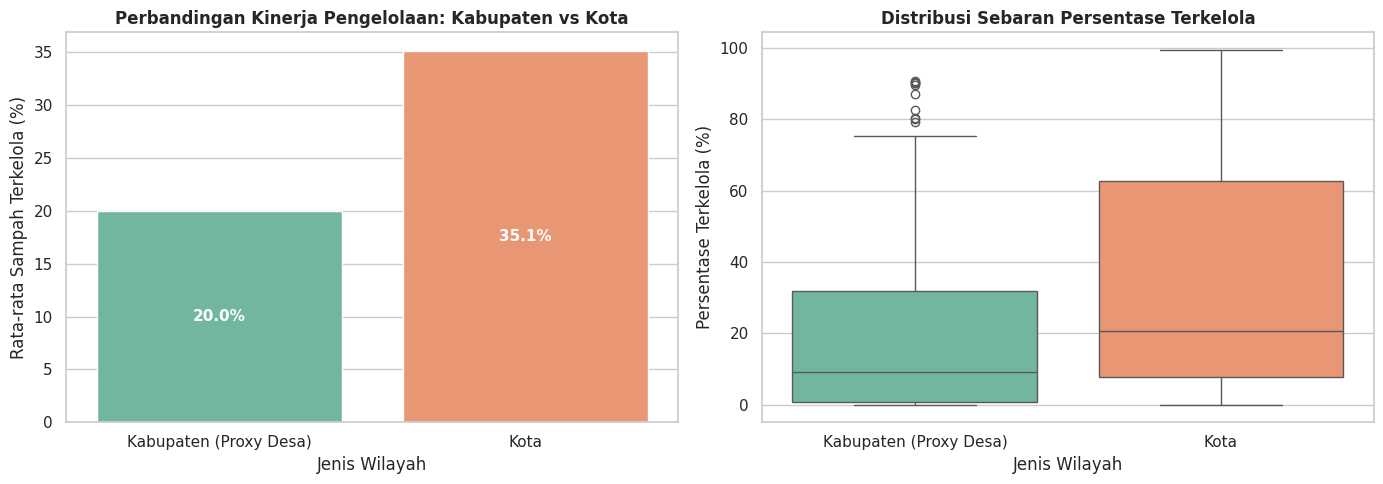

In [16]:
pola_jawa = 'Jawa|Banten|Jakarta|Yogyakarta'
mask_jawa = df_clean['Provinsi'].str.contains(pola_jawa, case=False, na=False)
prov_jawa = sorted(df_clean.loc[mask_jawa, 'Provinsi'].unique())
share_jawa = tim[mask_jawa].sum() / tim.sum()
print(f"Provinsi Pulau Jawa terdeteksi ({len(prov_jawa)}): {prov_jawa}")
print(f"Jumlah wilayah di Jawa: {int(mask_jawa.sum())} dari {len(df_clean)} ({mask_jawa.mean():.1%})")
print(f"Share timbulan Pulau Jawa: {share_jawa:.1%}")
top_prov = df_clean.groupby('Provinsi')['Timbulan (tpd)'].sum().sort_values(ascending=False)
print("5 provinsi dengan timbulan terbesar:")
print((top_prov.head(5) / tim.sum()).map('{:.1%}'.format).to_string())
print(f"Jumlah provinsi dalam data: {df_clean['Provinsi'].nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rep_summary, x='Jenis_Wilayah', y='mean', hue='Jenis_Wilayah', palette='Set2', ax=axes[0], legend=False)
axes[0].set_title('Perbandingan Kinerja Pengelolaan: Kabupaten vs Kota', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jenis Wilayah')
axes[0].set_ylabel('Rata-rata Sampah Terkelola (%)')
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')
sns.boxplot(data=df_clean, x='Jenis_Wilayah', y='% S. Terkelola', hue='Jenis_Wilayah', palette='Set2', ax=axes[1], legend=False)
axes[1].set_title('Distribusi Sebaran Persentase Terkelola', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jenis Wilayah')
axes[1].set_ylabel('Persentase Terkelola (%)')
simpan_fig('fig_kab_vs_kota.png')

### 4.3 Visualisasi fitur & target

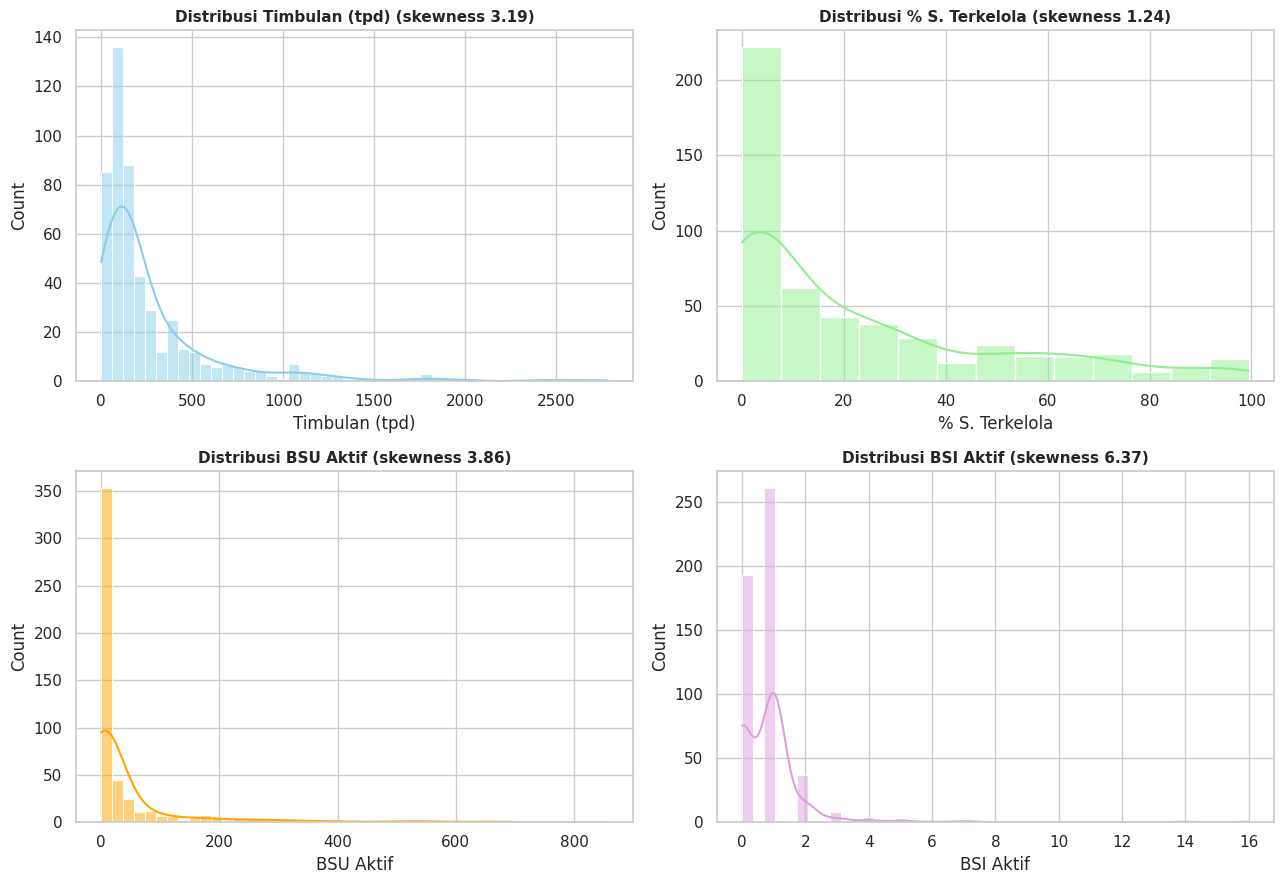

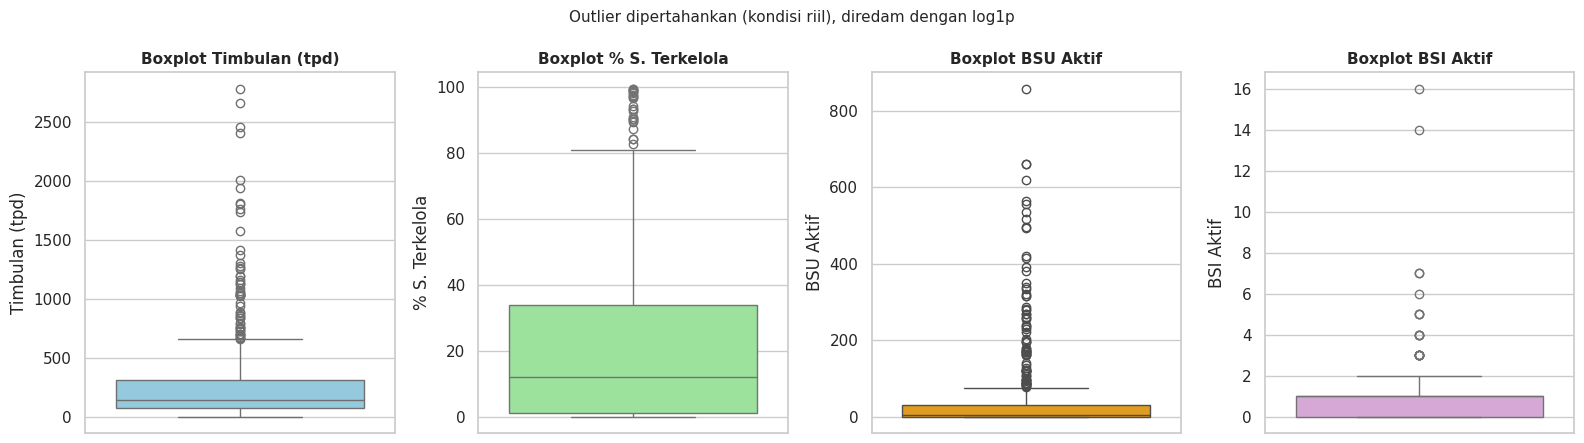

In [17]:
warna = ['skyblue', 'lightgreen', 'orange', 'plum']

# (a) Histogram semua fitur numerik
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, w in zip(axes.ravel(), numeric_features, warna):
    sns.histplot(df_clean[col], kde=True, ax=ax, color=w)
    ax.set_title(f'Distribusi {col} (skewness {df_clean[col].skew():.2f})', fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
simpan_fig('fig_distribusi_fitur.png')

# (b) Boxplot semua fitur numerik (outlier dipertahankan)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col, w in zip(axes, numeric_features, warna):
    sns.boxplot(y=df_clean[col], ax=ax, color=w)
    ax.set_title(f'Boxplot {col}', fontsize=11, fontweight='bold')
fig.suptitle('Outlier dipertahankan (kondisi riil), diredam dengan log1p', fontsize=11)
simpan_fig('fig_boxplot_fitur.png')

,Jenis TPA,count,mean
2,Sanitary Landfill,5,79.292
0,Controlled Landfill,132,53.810
4,Tidak memiliki TPA,22,13.446
1,Open Dumping,308,11.603
3,Tidak diisi,44,6.964


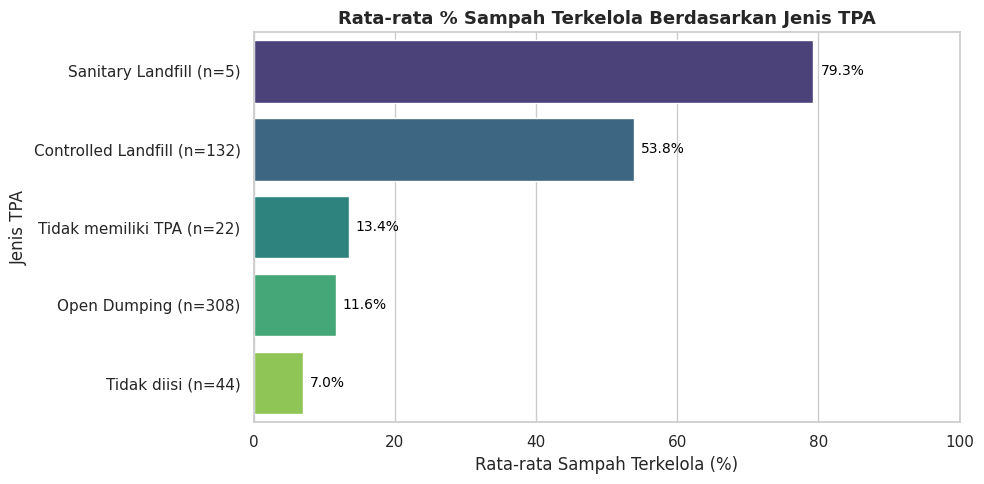

In [18]:
# (c) Kinerja berdasarkan Jenis TPA
tpa_perf = (df_clean.groupby('Jenis TPA')['% S. Terkelola'].agg(['mean', 'count'])
            .reset_index().sort_values('mean', ascending=False))
tpa_perf['Label'] = tpa_perf['Jenis TPA'] + ' (n=' + tpa_perf['count'].astype(str) + ')'
display(tpa_perf[['Jenis TPA', 'count', 'mean']])
simpan_tabel(tpa_perf, 'tabel_jenis_tpa.csv', index=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=tpa_perf, x='mean', y='Label', hue='Label', palette='viridis', legend=False)
plt.title('Rata-rata % Sampah Terkelola Berdasarkan Jenis TPA', fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata Sampah Terkelola (%)')
plt.ylabel('Jenis TPA')
for p in ax.patches:
    w = p.get_width()
    ax.annotate(f'{w:.1f}%', (w + 1, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontsize=10, color='black')
plt.xlim(0, 100)
simpan_fig('fig_jenis_tpa.png')

### 4.4 Korelasi Spearman & insight untuk pemodelan

,Timbulan (tpd),% S. Terkelola,BSU Aktif,BSI Aktif
Timbulan (tpd),1.000,0.265,0.647,0.363
% S. Terkelola,0.265,1.000,0.477,0.414
BSU Aktif,0.647,0.477,1.000,0.580
BSI Aktif,0.363,0.414,0.580,1.000


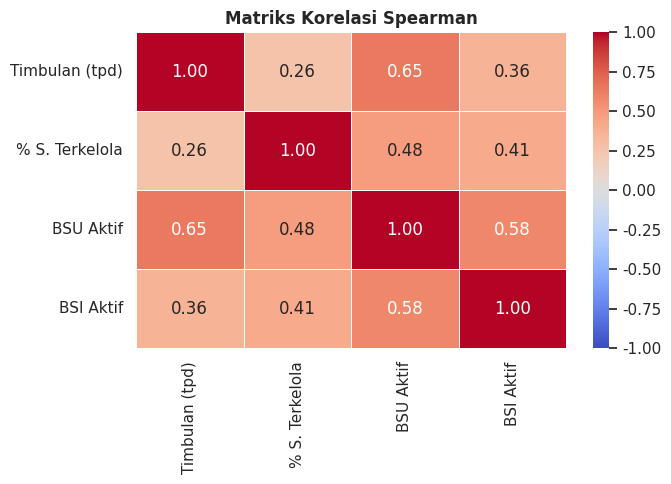

In [19]:
corr_matrix = df_clean[numeric_features].corr(method='spearman')
display(corr_matrix)
simpan_tabel(corr_matrix, 'tabel_korelasi_spearman.csv')
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriks Korelasi Spearman', fontsize=12, fontweight='bold')
simpan_fig('fig_korelasi.png')

In [20]:
c_tim_bsu = corr_matrix.loc['Timbulan (tpd)', 'BSU Aktif']
c_bsu_ter = corr_matrix.loc['BSU Aktif', '% S. Terkelola']
c_bsi_ter = corr_matrix.loc['BSI Aktif', '% S. Terkelola']
c_tim_ter = corr_matrix.loc['Timbulan (tpd)', '% S. Terkelola']
skew = df_clean[numeric_features].skew()
nol = df_clean[df_clean['% S. Terkelola'] == 0]
od_semua = (df_clean['Jenis TPA'] == 'Open Dumping').mean()
tanpa_terkendali = (~nol['Jenis TPA'].isin(['Controlled Landfill', 'Sanitary Landfill'])).mean()
tpa_nol = nol['Jenis TPA'].value_counts(normalize=True)
belum_verif_nol = nol['Flag_Belum_Verifikasi'].mean()

print("INSIGHT UNTUK KEPUTUSAN CLEANING/PEMODELAN (angka dihitung dari data):")
print(f"1. Skala: skewness fitur {skew.round(2).to_dict()}. Jarak Euclidean K-Means akan didominasi wilayah besar "
      f"(timbulan maks {tim.max():,.0f} vs median {tim.median():,.0f} tpd) -> perlu log1p + StandardScaler. "
      f"(Timbulan vs BSU Aktif: rho = {c_tim_bsu:.2f}, {kekuatan(c_tim_bsu)}.)")
print(f"2. Kandidat klaster prioritas: {len(nol)} wilayah ({len(nol) / len(df_clean):.1%}) dengan 0% terkelola; "
      f"{tanpa_terkendali:.1%} di antaranya tanpa TPA terkendali "
      f"(Open Dumping {tpa_nol.get('Open Dumping', 0):.1%}, TPA kosong {tpa_nol.get('Tidak diisi', 0):.1%}, "
      f"tidak punya TPA {tpa_nol.get('Tidak memiliki TPA', 0):.1%}); pembanding: Open Dumping pada seluruh wilayah = {od_semua:.1%}. "
      f"PERINGATAN: {belum_verif_nol:.1%} dari wilayah 0% ini belum diverifikasi lapangan, "
      f"jadi sebagian mungkin 'belum melapor', bukan 'tidak mengelola'.")
print(f"3. Proxy infrastruktur: BSU Aktif (rho = {c_bsu_ter:.2f}, {kekuatan(c_bsu_ter)}) dan BSI Aktif "
      f"(rho = {c_bsi_ter:.2f}, {kekuatan(c_bsi_ter)}) berkorelasi positif dengan % terkelola "
      f"(Timbulan: rho = {c_tim_ter:.2f}, {kekuatan(c_tim_ter)}) -> layak jadi fitur pengganti data perilaku rumah tangga. "
      f"Korelasi tidak membuktikan sebab-akibat.")

INSIGHT UNTUK KEPUTUSAN CLEANING/PEMODELAN (angka dihitung dari data):
1. Skala: skewness fitur {'Timbulan (tpd)': 3.19, '% S. Terkelola': 1.24, 'BSU Aktif': 3.86, 'BSI Aktif': 6.37}. Jarak Euclidean K-Means akan didominasi wilayah besar (timbulan maks 2,784 vs median 141 tpd) -> perlu log1p + StandardScaler. (Timbulan vs BSU Aktif: rho = 0.65, cukup kuat.)
2. Kandidat klaster prioritas: 64 wilayah (12.5%) dengan 0% terkelola; 98.4% di antaranya tanpa TPA terkendali (Open Dumping 50.0%, TPA kosong 37.5%, tidak punya TPA 10.9%); pembanding: Open Dumping pada seluruh wilayah = 60.3%. PERINGATAN: 31.2% dari wilayah 0% ini belum diverifikasi lapangan, jadi sebagian mungkin 'belum melapor', bukan 'tidak mengelola'.
3. Proxy infrastruktur: BSU Aktif (rho = 0.48, sedang) dan BSI Aktif (rho = 0.41, sedang) berkorelasi positif dengan % terkelola (Timbulan: rho = 0.26, lemah) -> layak jadi fitur pengganti data perilaku rumah tangga. Korelasi tidak membuktikan sebab-akibat.


### 4.5 Verifikasi angka klaim sebelumnya terhadap data

In [21]:
rips = df_clean.groupby('Status RIPS')['% S. Terkelola'].agg(['count', 'mean']).round(1)
rips_g = df_clean.groupby('RIPS_Grup')['% S. Terkelola'].agg(['count', 'mean']).round(1)
rata = rips_g['mean']
klaim = pd.DataFrame([
    ['Share timbulan Pulau Jawa', '55,3%', f'{share_jawa:.1%}'],
    ['Wilayah 0% terkelola', '64 wilayah / 12,5%', f'{len(nol)} wilayah / {len(nol) / len(df_clean):.1%}'],
    ['Wilayah < 10% terkelola', '47,2%', f'{persen_lt10:.1f}%'],
    ['Rata-rata % terkelola: RIPS disahkan vs tanpa RIPS', '33,2 vs 15,4', f"{rata.get('Disahkan', np.nan):.1f} vs {rata.get('Tidak ada', np.nan):.1f}"],
    ['Open Dumping', '60,3% (dikira khusus wilayah 0%)', f'{od_semua:.1%} dari SELURUH wilayah; pada wilayah 0% = {tpa_nol.get("Open Dumping", 0):.1%}'],
], columns=['Klaim', 'Klaim awal', 'Hasil dari data'])
display(klaim)
print("Rata-rata % terkelola per Status RIPS (rinci):")
display(rips)
print("Rata-rata % terkelola per kelompok RIPS (dipakai untuk interpretasi):")
display(rips_g)
print("3 timbulan terbesar:")
display(df_clean.nlargest(3, 'Timbulan (tpd)')[['Provinsi', 'Kota/Kabupaten', 'Timbulan (tpd)']])

,Klaim,Klaim awal,Hasil dari data
0,Share timbulan Pulau Jawa,"55,3%",55.3%
1,Wilayah 0% terkelola,"64 wilayah / 12,5%",64 wilayah / 12.5%
2,Wilayah < 10% terkelola,"47,2%",47.2%
3,Rata-rata % terkelola: RIPS disahkan vs tanpa ...,"33,2 vs 15,4",33.2 vs 15.4
4,Open Dumping,"60,3% (dikira khusus wilayah 0%)",60.3% dari SELURUH wilayah; pada wilayah 0% = ...


Rata-rata % terkelola per Status RIPS (rinci):


,count,mean
Status RIPS,,
Ada (Draft) tapi Belum Disahkan,47,31.800
Ada dan Sudah Disahkan,49,33.200
Ada tapi Belum Disahkan,82,35.200
Ada tapi File Belum Terlampir,2,18.500
Ada tapi Tidak Lengkap,5,27.000
Belum ada informasi,19,30.700
Dalam Perencanaan,16,23.300
Tidak Ada,271,15.400
Tidak Sesuai,5,18.000


Rata-rata % terkelola per kelompok RIPS (dipakai untuk interpretasi):


,count,mean
RIPS_Grup,,
"Ada, belum final",157,31.900
Disahkan,49,33.200
Tidak ada,271,15.400
Tidak diketahui,34,25.200


3 timbulan terbesar:


,Provinsi,Kota/Kabupaten,Timbulan (tpd)
0,Jawa Barat,Kabupaten Bogor,2784
1,Banten,Kabupaten Tangerang,2663
2,DKI Jakarta,Kota Jakarta Timur,2455


## 5. Data preprocessing & feature selection

### 5.1 Encoding kategorik (One-Hot) *untuk profiling, bukan input K-Means*

In [22]:
n_rips_asli, n_rips_grup = df_clean['Status RIPS'].nunique(), df_clean['RIPS_Grup'].nunique()
print(f"Status RIPS asli terlalu rinci ({n_rips_asli} kategori, sebagian hanya 2-5 wilayah), digabung menjadi {n_rips_grup} kelompok (RIPS_Grup):")
display(pd.crosstab(df_clean['Status RIPS'], df_clean['RIPS_Grup']))

df_enc = pd.get_dummies(df_clean[['Jenis TPA', 'RIPS_Grup', 'Jenis_Wilayah']], dtype=int)
print(f"One-hot menghasilkan {df_enc.shape[1]} kolom dari 3 variabel kategorik:")
print(list(df_enc.columns))
print("Alasan: K-Means memakai jarak Euclidean pada fitur numerik; kategorik dienkode one-hot hanya untuk "
      "profiling klaster (membandingkan komposisi TPA/RIPS per klaster) setelah klaster terbentuk.")
simpan_tabel(df_enc, 'tabel_encoding_onehot.csv')

Status RIPS asli terlalu rinci (10 kategori, sebagian hanya 2-5 wilayah), digabung menjadi 4 kelompok (RIPS_Grup):


RIPS_Grup,"Ada, belum final",Disahkan,Tidak ada,Tidak diketahui
Status RIPS,,,,
Ada (Draft) tapi Belum Disahkan,47,0,0,0
Ada dan Sudah Disahkan,0,49,0,0
Ada tapi Belum Disahkan,82,0,0,0
Ada tapi File Belum Terlampir,2,0,0,0
Ada tapi Tidak Lengkap,5,0,0,0
Belum ada informasi,0,0,0,19
Dalam Perencanaan,16,0,0,0
Tidak Ada,0,0,271,0
Tidak Sesuai,5,0,0,0


One-hot menghasilkan 11 kolom dari 3 variabel kategorik:
['Jenis TPA_Controlled Landfill', 'Jenis TPA_Open Dumping', 'Jenis TPA_Sanitary Landfill', 'Jenis TPA_Tidak diisi', 'Jenis TPA_Tidak memiliki TPA', 'RIPS_Grup_Ada, belum final', 'RIPS_Grup_Disahkan', 'RIPS_Grup_Tidak ada', 'RIPS_Grup_Tidak diketahui', 'Jenis_Wilayah_Kabupaten (Proxy Desa)', 'Jenis_Wilayah_Kota']
Alasan: K-Means memakai jarak Euclidean pada fitur numerik; kategorik dienkode one-hot hanya untuk profiling klaster (membandingkan komposisi TPA/RIPS per klaster) setelah klaster terbentuk.


### 5.2 Cek ketidakseimbangan kelas

In [23]:
imb_rows = []
for kol in ['Jenis_Wilayah', 'Jenis TPA', 'Status RIPS', 'RIPS_Grup']:
    vc = df_clean[kol].value_counts()
    imb_rows.append({'Variabel': kol, 'Kelas': len(vc),
                     'Mayoritas': f"{vc.index[0]} ({vc.iloc[0]})",
                     'Minoritas': f"{vc.index[-1]} ({vc.iloc[-1]})",
                     'Rasio_maks:min': round(vc.iloc[0] / vc.iloc[-1], 1)})
tabel_imbalance = pd.DataFrame(imb_rows).set_index('Variabel')
display(tabel_imbalance)
simpan_tabel(tabel_imbalance.reset_index(), 'tabel_imbalance.csv', index=False)
print("Ini clustering (tanpa label target), jadi tidak ada SMOTE/oversampling. Ketidakseimbangan ditangani dengan "
      "split berstrata pada Jenis_Wilayah, penggabungan kategori jarang (RIPS_Grup), dan diperhitungkan saat membaca profil klaster.")

,Kelas,Mayoritas,Minoritas,Rasio_maks:min
Variabel,,,,
Jenis_Wilayah,2,Kabupaten (Proxy Desa) (414),Kota (97),4.300
Jenis TPA,5,Open Dumping (308),Sanitary Landfill (5),61.600
Status RIPS,10,Tidak Ada (271),Ada tapi File Belum Terlampir (2),135.500
RIPS_Grup,4,Tidak ada (271),Tidak diketahui (34),8.000


Ini clustering (tanpa label target), jadi tidak ada SMOTE/oversampling. Ketidakseimbangan ditangani dengan split berstrata pada Jenis_Wilayah, penggabungan kategori jarang (RIPS_Grup), dan diperhitungkan saat membaca profil klaster.


### 5.3 Feature engineering & feature selection
Dua fitur turunan diuji: `Tidak_Terkelola_tpd` (beban sampah belum tertangani) dan `Total_Bank_Sampah`. Fitur turunan dibuang bila |ρ Spearman| dengan fitur dasar ≥ `AMBANG_REDUNDAN`.

> **Catatan metodologi:** ρ Spearman tinggi (mis. 0,86) berarti *urutan peringkat* mirip, bukan berarti dua fitur membawa informasi yang sama dalam ruang jarak K-Means. `Tidak_Terkelola_tpd` adalah interaksi (timbulan × (1 − %terkelola)) yang **tidak bisa dibentuk sendiri oleh K-Means**, dan secara substantif paling dekat dengan "beban prioritas". Karena itu fitur ini tetap dipakai di bagian 6 sebagai **ukuran profil** klaster, walau tidak menjadi input.

Tidak_Terkelola_tpd = Timbulan x (1 - %terkelola)  [beban sampah belum tertangani]
Total_Bank_Sampah   = BSU Aktif + BSI Aktif          [total kapasitas bank sampah]


,Timbulan (tpd),% S. Terkelola,BSU Aktif,BSI Aktif,Tidak_Terkelola_tpd,Total_Bank_Sampah
Timbulan (tpd),1.000,0.265,0.647,0.363,0.860,0.653
% S. Terkelola,0.265,1.000,0.477,0.414,-0.122,0.489
BSU Aktif,0.647,0.477,1.000,0.580,0.432,0.988
BSI Aktif,0.363,0.414,0.580,1.000,0.188,0.657
Tidak_Terkelola_tpd,0.860,-0.122,0.432,0.188,1.000,0.435
Total_Bank_Sampah,0.653,0.489,0.988,0.657,0.435,1.000


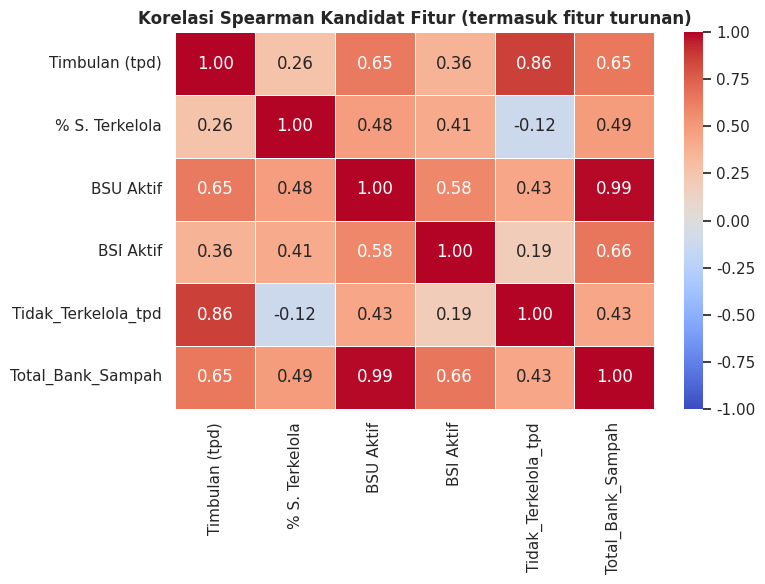

In [24]:
df_clean['Tidak_Terkelola_tpd'] = df_clean['Timbulan (tpd)'] * (1 - df_clean['% S. Terkelola'] / 100.0)
df_clean['Total_Bank_Sampah'] = df_clean['BSU Aktif'] + df_clean['BSI Aktif']
turunan = ['Tidak_Terkelola_tpd', 'Total_Bank_Sampah']
print("Tidak_Terkelola_tpd = Timbulan x (1 - %terkelola)  [beban sampah belum tertangani]")
print("Total_Bank_Sampah   = BSU Aktif + BSI Aktif          [total kapasitas bank sampah]")

kandidat = numeric_features + turunan
corr_kand = df_clean[kandidat].corr(method='spearman')
display(corr_kand)
simpan_tabel(corr_kand, 'tabel_korelasi_kandidat.csv')
plt.figure(figsize=(8, 6))
sns.heatmap(corr_kand, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Korelasi Spearman Kandidat Fitur (termasuk fitur turunan)', fontsize=12, fontweight='bold')
simpan_fig('fig_korelasi_kandidat.png')

In [25]:
keputusan = []
selected_features = list(numeric_features)
for f in numeric_features:
    alasan = f"skewness {df_clean[f].skew():.2f} (di-log1p); missing awal {tabel_audit.loc[f, 'Missing_%']:.1f}%"
    if f != '% S. Terkelola':
        alasan += f"; rho dengan % terkelola = {corr_kand.loc[f, '% S. Terkelola']:.2f}"
    else:
        alasan += "; indikator kinerja inti"
    keputusan.append([f, 'Dipakai', alasan])

for f in turunan:
    sisa = corr_kand.loc[f, numeric_features].abs()
    mitra, rho_max = sisa.idxmax(), sisa.max()
    if rho_max >= AMBANG_REDUNDAN:
        keputusan.append([f, 'Dibuang dari input (dipakai utk profil)' if f == 'Tidak_Terkelola_tpd' else 'Dibuang (redundan)',
                          f"|rho| dengan {mitra} = {rho_max:.2f} >= {AMBANG_REDUNDAN}; lihat catatan metodologi di atas"])
    else:
        selected_features.append(f)
        keputusan.append([f, 'Dipakai (fitur baru)', f"|rho| maks dengan fitur lain = {rho_max:.2f} < {AMBANG_REDUNDAN}; menambah informasi baru"])

for c in dibuang:
    alasan = "nomor urut, bukan informasi" if c == 'No' else f"missing {tabel_audit.loc[c, 'Missing_%']:.1f}%"
    keputusan.append([c, 'Dibuang', alasan])
for c in ['Jenis TPA', 'Status RIPS', 'Kelompok']:
    keputusan.append([c, 'Profiling saja', "kategorik; tidak cocok untuk jarak Euclidean K-Means, dipakai membaca profil klaster"])
keputusan.append(['RIPS_Grup', 'Profiling saja (fitur baru)',
                  f"penggabungan {n_rips_asli} status RIPS menjadi {n_rips_grup} kelompok agar one-hot tidak terlalu jarang"])

if '% S. Belum Terkelola' in df_clean.columns:
    belum = normalisasi_persen(ke_numerik(df_clean['% S. Belum Terkelola']))
    jumlah = df_clean['% S. Terkelola'] + belum
    rho_belum = df_clean['% S. Terkelola'].corr(belum, method='spearman')
    print(f"Cek '% S. Belum Terkelola': jumlah dengan % terkelola = {jumlah.min():.2f} s.d. {jumlah.max():.2f}; rho Spearman = {rho_belum:.2f}")
    if jumlah.between(99.5, 100.5).all():
        keputusan.append(['% S. Belum Terkelola', 'Dibuang (redundan)',
                          f"komplemen % terkelola (jumlah keduanya {jumlah.min():.1f}-{jumlah.max():.1f}%, rho = {rho_belum:.2f})"])
    else:
        keputusan.append(['% S. Belum Terkelola', 'Tidak dipakai', f"rho dengan % terkelola = {rho_belum:.2f}; tidak dipakai agar tidak menggandakan informasi"])

for c in ['Sampah Terkelola BSU', 'Sampah Terkelola BSI']:
    if c in df_clean.columns:
        df_clean[c] = ke_numerik(df_clean[c])
        mitra = 'BSU Aktif' if c.endswith('BSU') else 'BSI Aktif'
        rho_m = df_clean[c].corr(df_clean[mitra], method='spearman')
        rho_t = df_clean[c].corr(df_clean['% S. Terkelola'], method='spearman')
        pct_nol = (df_clean[c] == 0).mean() * 100
        if abs(rho_m) >= AMBANG_REDUNDAN:
            keputusan.append([c, 'Dibuang (redundan)', f"|rho| dengan {mitra} = {rho_m:.2f} >= {AMBANG_REDUNDAN}; {pct_nol:.0f}% bernilai 0"])
        else:
            keputusan.append([c, 'Tidak dipakai (kandidat UAS)',
                f"rho dengan {mitra} = {rho_m:.3f} (< {AMBANG_REDUNDAN}), rho dengan % terkelola = {rho_t:.2f}; "
                f"{pct_nol:.0f}% bernilai 0 dan satuan belum dikonfirmasi -> dievaluasi lagi"])

sudah = {k[0] for k in keputusan} | {'Provinsi', 'Kota/Kabupaten', 'Jenis_Wilayah', 'Split',
                                      'Flag_Timbulan_Nol', 'Flag_BSU_BSI_Kosong', 'Flag_Belum_Verifikasi', 'Verifikasi Lapangan'}
for c in df_clean.columns:
    if c not in sudah:
        keputusan.append([c, 'Tidak dipakai', 'di luar cakupan indikator model / metadata'])
keputusan.append(['Verifikasi Lapangan', 'Flag kualitas data', 'status Sudah/Belum dijadikan Flag_Belum_Verifikasi; tidak masuk model'])
keputusan.append(['Flag_*', 'Flag kualitas data', 'tidak masuk model; dipakai untuk uji sensitivitas klaster (bagian 6.5)'])
keputusan.append(['Provinsi, Kota/Kabupaten', 'Identitas', 'label wilayah untuk interpretasi hasil klaster'])

tabel_keputusan = pd.DataFrame(keputusan, columns=['Fitur/Kolom', 'Keputusan', 'Alasan & bukti'])
with pd.option_context('display.max_colwidth', 140):
    display(tabel_keputusan)
simpan_tabel(tabel_keputusan, 'tabel_keputusan_fitur.csv', index=False)
print(f"\nFitur akhir K-Means ({len(selected_features)}): {selected_features}")

Cek '% S. Belum Terkelola': jumlah dengan % terkelola = 100.00 s.d. 100.00; rho Spearman = -1.00


,Fitur/Kolom,Keputusan,Alasan & bukti
0,Timbulan (tpd),Dipakai,skewness 3.19 (di-log1p); missing awal 0.0%; rho dengan % terkelola = 0.26
1,% S. Terkelola,Dipakai,skewness 1.24 (di-log1p); missing awal 0.0%; indikator kinerja inti
2,BSU Aktif,Dipakai,skewness 3.86 (di-log1p); missing awal 5.1%; rho dengan % terkelola = 0.48
3,BSI Aktif,Dipakai,skewness 6.37 (di-log1p); missing awal 5.7%; rho dengan % terkelola = 0.41
4,Tidak_Terkelola_tpd,Dibuang dari input (dipakai utk profil),|rho| dengan Timbulan (tpd) = 0.86 >= 0.8; lihat catatan metodologi di atas
5,Total_Bank_Sampah,Dibuang (redundan),|rho| dengan BSU Aktif = 0.99 >= 0.8; lihat catatan metodologi di atas
6,Nama TPA,Dibuang,missing 100.0%
7,Nilai Kinerja PS,Dibuang,missing 100.0%
8,Progress SA,Dibuang,missing 57.3%
9,Link RIPS,Dibuang,missing 73.0%



Fitur akhir K-Means (4): ['Timbulan (tpd)', '% S. Terkelola', 'BSU Aktif', 'BSI Aktif']


### 5.4 Split train/test + log1p + StandardScaler
`StandardScaler` di-*fit* **hanya pada data train**. `log1p` dipakai karena terbukti menurunkan skewness (kolom `Timbulan` dari ±3 ke ±0). Perlu dicatat bahwa `BSI Aktif` hampir biner (sebagian besar bernilai 0 atau 1) dan banyak bernilai nol, jadi kontribusinya ke jarak lebih seperti "ada/tidak ada" daripada gradasi.

In [26]:
prop = pd.DataFrame({
    'Seluruh': df_clean['Jenis_Wilayah'].value_counts(normalize=True),
    'Train': df_clean.loc[idx_train, 'Jenis_Wilayah'].value_counts(normalize=True),
    'Test': df_clean.loc[idx_test, 'Jenis_Wilayah'].value_counts(normalize=True),
})
print(f"Split {int((1 - TEST_SIZE) * 100)}/{int(TEST_SIZE * 100)}, stratify=Jenis_Wilayah, random_state={RANDOM_STATE}")
print("Proporsi Jenis_Wilayah (membuktikan stratifikasi terjaga):")
display(prop)

skew_cek = pd.DataFrame({'skew_asli': df_clean[selected_features].skew(),
                         'skew_log1p': np.log1p(df_clean[selected_features]).skew(),
                         'proporsi_nol': (df_clean[selected_features] == 0).mean()})
print("Efek log1p pada skewness:")
display(skew_cek)

scaler = StandardScaler()
scaler.fit(np.log1p(df_clean.loc[idx_train, selected_features]))      # fit HANYA di train
X_train = scaler.transform(np.log1p(df_clean.loc[idx_train, selected_features]))
X_test = scaler.transform(np.log1p(df_clean.loc[idx_test, selected_features]))
assert not np.isnan(X_train).any() and not np.isnan(X_test).any()
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print("Mean X_train per fitur (harus ~0):", X_train.mean(axis=0).round(3))
print("Std  X_train per fitur (harus ~1):", X_train.std(axis=0).round(3))
print("Mean X_test  per fitur (boleh menyimpang sedikit):", X_test.mean(axis=0).round(3))

Split 80/20, stratify=Jenis_Wilayah, random_state=42
Proporsi Jenis_Wilayah (membuktikan stratifikasi terjaga):


,Seluruh,Train,Test
Jenis_Wilayah,,,
Kabupaten (Proxy Desa),0.810,0.811,0.806
Kota,0.190,0.189,0.194


Efek log1p pada skewness:


,skew_asli,skew_log1p,proporsi_nol
Timbulan (tpd),3.187,0.064,0.002
% S. Terkelola,1.239,-0.194,0.125
BSU Aktif,3.860,0.632,0.264
BSI Aktif,6.369,0.785,0.378


X_train: (408, 4) | X_test: (103, 4)
Mean X_train per fitur (harus ~0): [ 0.  0. -0. -0.]
Std  X_train per fitur (harus ~1): [1. 1. 1. 1.]
Mean X_test  per fitur (boleh menyimpang sedikit): [-0.069  0.249  0.194 -0.047]


### 5.5 Matriks fitur akhir

In [27]:
X_all = scaler.transform(np.log1p(df_clean[selected_features]))
df_scaled = pd.DataFrame(X_all, index=df_clean.index, columns=[f"{c}_scaled" for c in selected_features])
df_final_model = pd.concat(
    [df_clean[['Provinsi', 'Kota/Kabupaten', 'Jenis_Wilayah', 'Split']], df_scaled], axis=1)
print(f"Total wilayah: {df_final_model.shape[0]} | Jumlah fitur: {len(selected_features)} | train: {len(idx_train)} | test: {len(idx_test)}")
simpan_tabel(df_final_model, 'fitur_akhir_kmeans.csv', index=False)
simpan_tabel(df_clean, 'data_bersih.csv', index=False)
df_final_model.head()

Total wilayah: 511 | Jumlah fitur: 4 | train: 408 | test: 103


,Provinsi,Kota/Kabupaten,Jenis_Wilayah,Split,Timbulan (tpd)_scaled,% S. Terkelola_scaled,BSU Aktif_scaled,BSI Aktif_scaled
0,Jawa Barat,Kabupaten Bogor,Kabupaten (Proxy Desa),train,2.746,0.610,2.191,3.084
1,Banten,Kabupaten Tangerang,Kabupaten (Proxy Desa),test,2.704,-0.339,1.574,0.402
2,DKI Jakarta,Kota Jakarta Timur,Kota,test,2.626,0.421,2.118,0.402
3,Jawa Barat,Kabupaten Bekasi,Kabupaten (Proxy Desa),train,2.605,-0.605,1.976,-1.083
4,DKI Jakarta,Kota Jakarta Selatan,Kota,train,2.431,0.547,2.336,0.402


## 6. Pemodelan K-Means *(baru)*
Bagian ini sebelumnya belum ada di skrip `.py`. Prinsipnya: model di-*fit* pada **data train**, lalu seluruh wilayah (train + test) diberi label klaster lewat `predict`. Skor pada data test dipakai untuk mengecek apakah struktur klaster ikut berlaku pada data yang tidak dipakai melatih model.

### 6.1 Memilih jumlah klaster (K)

,Inertia (WCSS),Silhouette train,Silhouette test,Davies-Bouldin (turun=bagus),Calinski-Harabasz
K,,,,,
2,944.984,0.360,0.377,1.092,295.167
3,754.798,0.299,0.321,1.235,235.339
4,647.276,0.290,0.321,1.249,204.873
5,556.564,0.319,0.334,1.140,194.677
6,489.130,0.322,0.311,1.136,187.857
7,432.159,0.327,0.310,1.088,185.555
8,394.127,0.313,0.258,1.059,179.474
9,358.953,0.299,0.231,1.081,176.885
10,330.955,0.311,0.244,1.061,173.846


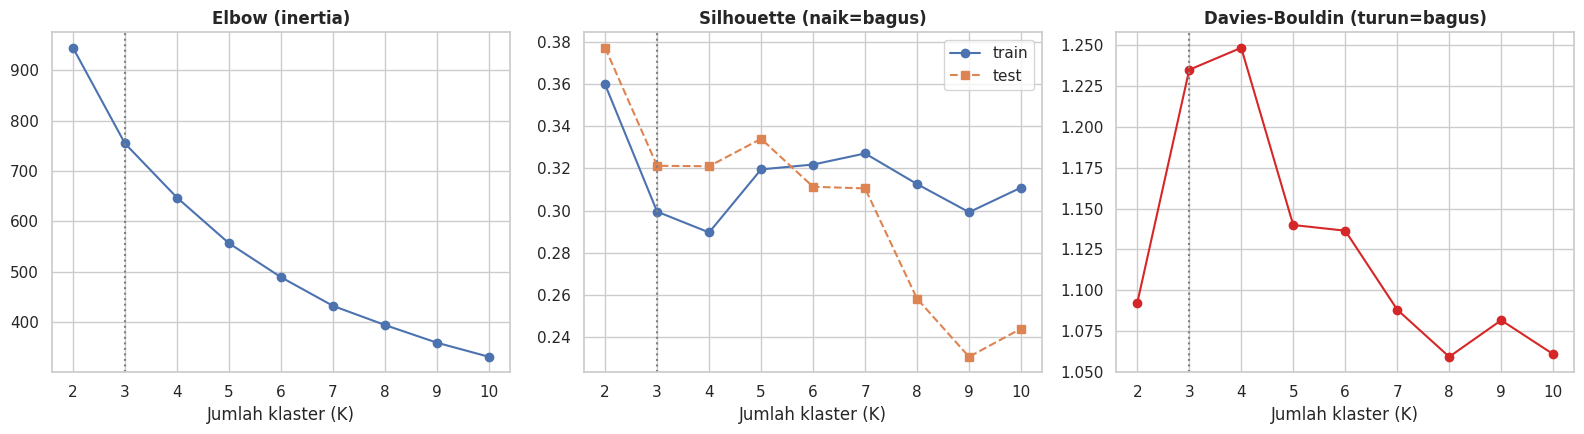

K dengan silhouette tertinggi: 2 (skor 0.360) | K_AKHIR yang dipakai: 3


In [28]:
rows = []
for k in range(K_MIN, K_MAX + 1):
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(X_train)
    rows.append({
        'K': k,
        'Inertia (WCSS)': km.inertia_,
        'Silhouette train': silhouette_score(X_train, km.labels_),
        'Silhouette test': silhouette_score(X_test, km.predict(X_test)),
        'Davies-Bouldin (turun=bagus)': davies_bouldin_score(X_train, km.labels_),
        'Calinski-Harabasz': calinski_harabasz_score(X_train, km.labels_),
    })
tabel_k = pd.DataFrame(rows).set_index('K')
display(tabel_k)
simpan_tabel(tabel_k, 'tabel_pemilihan_k.csv')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(tabel_k.index, tabel_k['Inertia (WCSS)'], 'o-')
axes[0].set_title('Elbow (inertia)', fontweight='bold')
axes[1].plot(tabel_k.index, tabel_k['Silhouette train'], 'o-', label='train')
axes[1].plot(tabel_k.index, tabel_k['Silhouette test'], 's--', label='test')
axes[1].set_title('Silhouette (naik=bagus)', fontweight='bold'); axes[1].legend()
axes[2].plot(tabel_k.index, tabel_k['Davies-Bouldin (turun=bagus)'], 'o-', color='tab:red')
axes[2].set_title('Davies-Bouldin (turun=bagus)', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Jumlah klaster (K)'); ax.axvline(K_AKHIR, color='gray', ls=':', label=None)
simpan_fig('fig_pemilihan_k.png')

k_sil = int(tabel_k['Silhouette train'].idxmax())
print(f"K dengan silhouette tertinggi: {k_sil} (skor {tabel_k.loc[k_sil, 'Silhouette train']:.3f}) | K_AKHIR yang dipakai: {K_AKHIR}")

**Cara membaca:** skor silhouette berada di kisaran ±0,3, yaitu struktur klaster **ada tetapi lemah**: data SIPSN lebih mirip kontinum daripada kelompok yang terpisah tegas, dan kurva elbow tidak punya siku yang jelas. Metrik cenderung memilih K = 2 (hanya memisahkan wilayah "tertinggal" dari sisanya), yang terlalu kasar untuk menentukan prioritas intervensi. `K_AKHIR = 3` dipilih sebagai kompromi antara metrik dan keterbacaan. Itu **keputusan penilaian, bukan hasil optimasi**; ubah di sel konfigurasi dan jalankan ulang bila ingin K lain.

### 6.2 Model akhir & profil klaster

In [29]:
def fit_cluster(d, fitur, k, seed=RANDOM_STATE, n_init=N_INIT):
    """log1p + StandardScaler (fit di train) + K-Means (fit di train). Mengembalikan label SELURUH baris di d."""
    tr = d['Split'].eq('train').values
    sc = StandardScaler().fit(np.log1p(d.loc[tr, fitur]))
    Xa = sc.transform(np.log1p(d[fitur]))
    km = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(Xa[tr])
    return km.predict(Xa), km, sc, Xa


label_ref, km_final, scaler_final, X_final = fit_cluster(df_clean, selected_features, K_AKHIR)
df_model = df_clean.copy()
df_model['Klaster'] = label_ref
print(f"Silhouette seluruh wilayah: {silhouette_score(X_final, label_ref):.3f} | "
      f"train: {silhouette_score(X_final[df_model['Split'].eq('train').values], label_ref[df_model['Split'].eq('train').values]):.3f} | "
      f"test: {silhouette_score(X_final[df_model['Split'].eq('test').values], label_ref[df_model['Split'].eq('test').values]):.3f}")

profil = df_model.groupby('Klaster').agg(
    Jumlah=('Klaster', 'size'),
    Timbulan_median=('Timbulan (tpd)', 'median'),
    Terkelola_median_pct=('% S. Terkelola', 'median'),
    BSU_median=('BSU Aktif', 'median'),
    BSI_median=('BSI Aktif', 'median'),
    Pct_Kota=('Jenis_Wilayah', lambda s: (s == 'Kota').mean() * 100),
    Wilayah_0pct=('% S. Terkelola', lambda s: int((s == 0).sum())),
    Belum_Verifikasi=('Flag_Belum_Verifikasi', 'sum'),
    Tidak_Terkelola_total_tpd=('Tidak_Terkelola_tpd', 'sum'),
)
profil['Share_beban_tidak_terkelola_pct'] = profil['Tidak_Terkelola_total_tpd'] / profil['Tidak_Terkelola_total_tpd'].sum() * 100
display(profil)
simpan_tabel(profil, 'tabel_profil_klaster.csv')


def tingkat(med, seri):
    """Posisi median klaster di antara seluruh wilayah (midrank), diberi label rendah/sedang/tinggi."""
    pr = ((seri < med).mean() + (seri <= med).mean()) / 2
    return 'rendah' if pr < 0.33 else 'sedang' if pr < 0.67 else 'tinggi'


print("Ringkasan otomatis tiap klaster:")
for k, g in df_model.groupby('Klaster'):
    deskripsi = ', '.join(f"{f.split(' (')[0]} {tingkat(g[f].median(), df_model[f])}" for f in numeric_features)
    print(f"- Klaster {k} (n={len(g)}, {g['Tidak_Terkelola_tpd'].sum() / df_model['Tidak_Terkelola_tpd'].sum():.0%} dari beban "
          f"sampah tidak terkelola): {deskripsi}")

Silhouette seluruh wilayah: 0.302 | train: 0.296 | test: 0.317


,Jumlah,Timbulan_median,Terkelola_median_pct,BSU_median,BSI_median,Pct_Kota,Wilayah_0pct,Belum_Verifikasi,Tidak_Terkelola_total_tpd,Share_beban_tidak_terkelola_pct
Klaster,,,,,,,,,,
0,180,77.500,0.385,0.000,0.000,5.000,64,22,"19,852.934",18.287
1,185,126.000,30.240,4.000,1.000,22.162,0,2,"17,869.109",16.460
2,146,488.500,22.210,76.000,1.000,32.192,0,0,"70,841.257",65.253


Ringkasan otomatis tiap klaster:
- Klaster 0 (n=180, 18% dari beban sampah tidak terkelola): Timbulan rendah, % S. Terkelola rendah, BSU Aktif rendah, BSI Aktif rendah
- Klaster 1 (n=185, 16% dari beban sampah tidak terkelola): Timbulan sedang, % S. Terkelola tinggi, BSU Aktif sedang, BSI Aktif sedang
- Klaster 2 (n=146, 65% dari beban sampah tidak terkelola): Timbulan tinggi, % S. Terkelola sedang, BSU Aktif tinggi, BSI Aktif sedang


**Membaca prioritas:** jangan menyamakan "persentase terkelola paling rendah" dengan "paling prioritas". Kolom `Share_beban_tidak_terkelola_pct` menunjukkan **di klaster mana tumpukan sampah tak tertangani paling besar secara absolut (ton/hari)**. Klaster dengan persentase menengah tetapi volume besar bisa menanggung beban absolut lebih besar daripada klaster 0%-terkelola yang wilayahnya kecil. Keduanya relevan dengan alasan berbeda: yang satu soal **cakupan layanan**, yang lain soal **volume**.

### 6.3 Visualisasi klaster (PCA 2D)

Varians dijelaskan PC1 + PC2: 78.1%
Loading PCA:


,PC1,PC2
Timbulan (tpd),0.517,-0.642
% S. Terkelola,0.430,0.683
BSU Aktif,0.591,-0.167
BSI Aktif,0.446,0.306


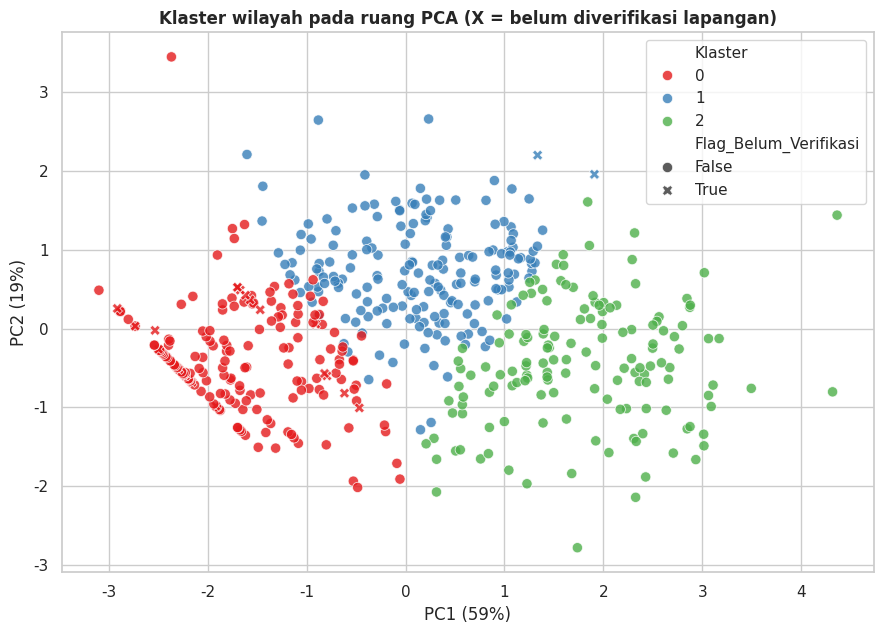

In [30]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_final)
Z = pca.transform(X_final)
df_model['PC1'], df_model['PC2'] = Z[:, 0], Z[:, 1]
print(f"Varians dijelaskan PC1 + PC2: {pca.explained_variance_ratio_.sum():.1%}")
print("Loading PCA:")
display(pd.DataFrame(pca.components_.T, index=selected_features, columns=['PC1', 'PC2']))

plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=df_model, x='PC1', y='PC2', hue='Klaster', style='Flag_Belum_Verifikasi',
                markers={False: 'o', True: 'X'}, palette='Set1', s=55, alpha=0.8)
plt.title('Klaster wilayah pada ruang PCA (X = belum diverifikasi lapangan)', fontsize=12, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
simpan_fig('fig_pca_klaster.png')

### 6.4 Profil kategorik per klaster (validasi eksternal)

In [31]:
for kol in ['Jenis TPA', 'RIPS_Grup', 'Jenis_Wilayah', 'Kelompok', 'Verifikasi Lapangan']:
    print(f"Komposisi {kol} per klaster (% baris):")
    display((pd.crosstab(df_model['Klaster'], df_model[kol], normalize='index') * 100).round(1))

print("Wilayah per provinsi di tiap klaster (5 provinsi terbanyak per klaster):")
for k, g in df_model.groupby('Klaster'):
    print(f"  Klaster {k}:", g['Provinsi'].value_counts().head(5).to_dict())
hasil = df_model[['Provinsi', 'Kota/Kabupaten', 'Jenis_Wilayah', 'Split', 'Klaster'] + numeric_features +
                 ['Tidak_Terkelola_tpd', 'Jenis TPA', 'RIPS_Grup', 'Flag_Timbulan_Nol', 'Flag_BSU_BSI_Kosong', 'Flag_Belum_Verifikasi']]
simpan_tabel(hasil.sort_values(['Klaster', 'Tidak_Terkelola_tpd'], ascending=[True, False]), 'hasil_klaster.csv', index=False)

Komposisi Jenis TPA per klaster (% baris):


Jenis TPA,Controlled Landfill,Open Dumping,Sanitary Landfill,Tidak diisi,Tidak memiliki TPA
Klaster,,,,,
0,3.900,71.700,0.000,17.200,7.200
1,47.600,43.200,0.500,5.400,3.200
2,25.300,67.800,2.700,2.100,2.100


Komposisi RIPS_Grup per klaster (% baris):


RIPS_Grup,"Ada, belum final",Disahkan,Tidak ada,Tidak diketahui
Klaster,,,,
0,14.400,1.100,81.700,2.800
1,29.200,7.000,51.400,12.400
2,52.700,23.300,19.900,4.100


Komposisi Jenis_Wilayah per klaster (% baris):


Jenis_Wilayah,Kabupaten (Proxy Desa),Kota
Klaster,,
0,95.000,5.000
1,77.800,22.200
2,67.800,32.200


Komposisi Kelompok per klaster (% baris):


Kelompok,343 TPA (353 Kota/Kab),Diluar 343 TPA (171 Kota/Kab)
Klaster,,
0,90.000,10.000
1,51.900,48.100
2,52.100,47.900


Komposisi Verifikasi Lapangan per klaster (% baris):


Verifikasi Lapangan,Belum,Sudah
Klaster,,
0,12.200,87.800
1,1.100,98.900
2,0.000,100.000


Wilayah per provinsi di tiap klaster (5 provinsi terbanyak per klaster):
  Klaster 0: {'Sumatera Utara': 21, 'Aceh': 13, 'Kalimantan Barat': 12, 'Maluku': 10, 'Kalimantan Tengah': 9}
  Klaster 1: {'Nusa Tenggara Timur': 20, 'Sumatera Barat': 16, 'Sulawesi Selatan': 16, 'Kalimantan Selatan': 10, 'Aceh': 9}
  Klaster 2: {'Jawa Timur': 30, 'Jawa Tengah': 29, 'Jawa Barat': 24, 'Bali': 8, 'Banten': 7}


### 6.5 Uji stabilitas & sensitivitas
Tiga pertanyaan: (a) apakah hasil bergantung pada *random seed*? (b) apakah hasil berubah bila wilayah dengan data meragukan (belum verifikasi / timbulan 0) dikeluarkan? (c) apakah hasil berubah bila `-` pada BSU/BSI dianggap 0, bukan median? Ukurannya **Adjusted Rand Index (ARI)** terhadap model akhir: 1 = klaster identik, 0 = setara acak. Aturan praktis: ARI ≥ 0,8 dianggap stabil.

In [32]:
sens = []

# (a) stabilitas terhadap seed
ari_1 = [adjusted_rand_score(label_ref, fit_cluster(df_clean, selected_features, K_AKHIR, seed=s, n_init=1)[0]) for s in range(20)]
ari_n = [adjusted_rand_score(label_ref, fit_cluster(df_clean, selected_features, K_AKHIR, seed=s, n_init=N_INIT)[0]) for s in range(20)]
sens.append(['Seed berbeda, n_init=1 (20 kali)', f'min {min(ari_1):.2f} | rata-rata {np.mean(ari_1):.2f}', len(df_clean)])
sens.append([f'Seed berbeda, n_init={N_INIT} (20 kali)', f'min {min(ari_n):.2f} | rata-rata {np.mean(ari_n):.2f}', len(df_clean)])

# (b) keluarkan wilayah meragukan
ok = ~(df_clean['Flag_Belum_Verifikasi'] | df_clean['Flag_Timbulan_Nol'])
lab_sub = fit_cluster(df_clean[ok], selected_features, K_AKHIR)[0]
sens.append([f'Tanpa wilayah belum-verifikasi/timbulan-0 (-{int((~ok).sum())} wilayah)',
             f"{adjusted_rand_score(label_ref[ok.values], lab_sub):.2f}", int(ok.sum())])

# (c) imputasi BSU/BSI = 0 (bukan median)
d_nol = df_clean.copy()
for c in ['BSU Aktif', 'BSI Aktif']:
    d_nol.loc[num_before[c].isna(), c] = 0
lab_nol = fit_cluster(d_nol, selected_features, K_AKHIR)[0]
sens.append(['Imputasi BSU/BSI = 0 (bukan median)', f"{adjusted_rand_score(label_ref, lab_nol):.2f}", len(df_clean)])

tabel_sens = pd.DataFrame(sens, columns=['Skenario', 'ARI terhadap model akhir', 'n wilayah'])
display(tabel_sens)
simpan_tabel(tabel_sens, 'tabel_sensitivitas.csv', index=False)

ari_kunci = [min(ari_n), adjusted_rand_score(label_ref[ok.values], lab_sub), adjusted_rand_score(label_ref, lab_nol)]
print("Catatan: label klaster antar-model bisa tertukar nomor, sehingga ARI (bukan kesamaan label) yang dibaca.")
print("Verdict: " + ("STABIL, semua skenario utama ARI >= 0,8; klaster tidak bergantung pada seed, wilayah meragukan, maupun metode imputasi."
                     if min(ari_kunci) >= 0.8 else
                     f"WASPADA, ada skenario dengan ARI {min(ari_kunci):.2f} (< 0,8); klaster sensitif, laporkan sebagai keterbatasan."))
print(f"Dampak n_init: n_init=1 bisa menghasilkan ARI serendah {min(ari_1):.2f}, karena itu N_INIT={N_INIT} dipakai.")

,Skenario,ARI terhadap model akhir,n wilayah
0,"Seed berbeda, n_init=1 (20 kali)",min 0.73 | rata-rata 0.90,511
1,"Seed berbeda, n_init=20 (20 kali)",min 0.92 | rata-rata 0.95,511
2,Tanpa wilayah belum-verifikasi/timbulan-0 (-25...,0.89,486
3,Imputasi BSU/BSI = 0 (bukan median),0.92,511


Catatan: label klaster antar-model bisa tertukar nomor, sehingga ARI (bukan kesamaan label) yang dibaca.
Verdict: STABIL, semua skenario utama ARI >= 0,8; klaster tidak bergantung pada seed, wilayah meragukan, maupun metode imputasi.
Dampak n_init: n_init=1 bisa menghasilkan ARI serendah 0.73, karena itu N_INIT=20 dipakai.


## 7. Kesimpulan & keterbatasan

**Yang bisa disimpulkan dengan cukup aman**
- Data SIPSN per kabupaten/kota konsisten dengan tabel ringkasan nasional di file yang sama (total timbulan dan % terkelola tertimbang cocok), sehingga pipeline pembacaan data tidak salah angka.
- Pengelolaan sampah sangat timpang: sekitar dua pertiga wilayah mengelola kurang dari seperempat sampahnya, rata-rata % terkelola wilayah ber-TPA Controlled/Sanitary jauh di atas Open Dumping (hubungan, bukan sebab-akibat), dan lebih dari separuh timbulan berada di Pulau Jawa.
- Klaster dapat dibaca sebagai tingkatan kombinasi *volume × kinerja × infrastruktur bank sampah*, dan klaster "kinerja terendah" memuat seluruh wilayah 0% terkelola.

**Keterbatasan yang wajib disebut saat presentasi**
1. **Struktur klaster lemah** (silhouette ±0,3): batas antar klaster bersifat kabur, jadi gunakan sebagai *tingkatan prioritas*, bukan kategori tegas.
2. **Kualitas data:** sebagian wilayah "0% terkelola" belum diverifikasi lapangan atau tidak melapor `BSU/BSI/Jenis TPA`. Nilai 0% bisa berarti *tidak melapor*, bukan *tidak mengelola*. Lihat uji 6.5(b).
3. **"Kabupaten = proxy perdesaan" lemah:** sebagian besar kabupaten tidak perdesaan menurut kategori ukuran SIPSN sendiri, dan unit analisis kabupaten/kota tidak bisa menjawab kondisi tingkat desa.
4. **Snapshot satu periode (2026):** tidak ada dimensi waktu, sehingga tren dan kausalitas tidak bisa disimpulkan. Korelasi ≠ sebab-akibat.
5. **Fitur `BSU/BSI` hanya proxy infrastruktur**, bukan perilaku rumah tangga; `BSI Aktif` hampir biner (0/1).
6. **Dua ukuran "terkelola":** persentase (cakupan) dan ton/hari (volume) memberi urutan prioritas berbeda; laporkan keduanya.
7. Satuan `Sampah Terkelola BSU/BSI` belum dikonfirmasi, jadi belum dipakai sebagai fitur.

**Pengembangan lanjutan:** uji algoritma lain (Gaussian Mixture, hierarchical, K-Medoids) pada fitur yang sama; tambahkan data penduduk/PDRB/luas wilayah dari sumber lain agar proxy perdesaan dan intensitas per kapita bisa dihitung; pertimbangkan membuat klaster terpisah untuk wilayah ber-data-meragukan.

In [33]:
print("Semua grafik & tabel tersimpan di:", OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    print("  -", f.name)

Semua grafik & tabel tersimpan di: c:\ds\clustering-pengelolaan-sampah-sipsn-notebook\clustering-pengelolaan-sampah-sipsn\output
  - data_bersih.csv
  - fig_boxplot_fitur.png
  - fig_distribusi_fitur.png
  - fig_jenis_tpa.png
  - fig_kab_vs_kota.png
  - fig_korelasi.png
  - fig_korelasi_kandidat.png
  - fig_pca_klaster.png
  - fig_pemilihan_k.png
  - fitur_akhir_kmeans.csv
  - hasil_klaster.csv
  - tabel_audit_kolom.csv
  - tabel_encoding_onehot.csv
  - tabel_imbalance.csv
  - tabel_jenis_tpa.csv
  - tabel_kabupaten_vs_kota.csv
  - tabel_kamus_data.csv
  - tabel_keputusan_fitur.csv
  - tabel_korelasi_kandidat.csv
  - tabel_korelasi_spearman.csv
  - tabel_pemilihan_k.csv
  - tabel_profil_klaster.csv
  - tabel_sebelum_sesudah_kategori.csv
  - tabel_sebelum_sesudah_numerik.csv
  - tabel_sensitivitas.csv
  - tabel_statistik_deskriptif.csv
